# DATASET LOADING

In [3]:

import pandas as pd
import os

# ============================================================
# STEP 1: DATASET INSPECTION
# ============================================================

dataset_path = r"E:\Projects\5_Data Mining\Dataset\IoT_Learning_Motivation_Dataset.csv"

# Check whether the dataset exists
if not os.path.exists(dataset_path):
    raise FileNotFoundError(f"Dataset not found: {dataset_path}")

# Load dataset without modifying or saving any files
df = pd.read_csv(dataset_path)

print("=" * 80)
print("IOT LEARNING MOTIVATION DATASET INSPECTION")
print("=" * 80)

# 1. Dataset dimensions
print("\n1. DATASET SHAPE")
print("-" * 80)
print(f"Number of rows    : {df.shape[0]}")
print(f"Number of columns : {df.shape[1]}")
print(f"Total cells       : {df.size}")

# 2. Column names
print("\n2. COLUMN NAMES")
print("-" * 80)
for i, column in enumerate(df.columns, start=1):
    print(f"{i:2d}. {column}")

# 3. First five records
print("\n3. FIRST FIVE RECORDS")
print("-" * 80)
print(df.head())

# 4. Data types
print("\n4. COLUMN DATA TYPES")
print("-" * 80)
print(df.dtypes.to_string())

# 5. Missing values
print("\n5. MISSING VALUE ANALYSIS")
print("-" * 80)
missing = df.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})
print(missing_summary.to_string())

print(f"\nTotal missing values: {df.isnull().sum().sum()}")

# 6. Duplicate rows
print("\n6. DUPLICATE ROW ANALYSIS")
print("-" * 80)
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

# 7. Descriptive statistics
print("\n7. NUMERICAL DESCRIPTIVE STATISTICS")
print("-" * 80)
print(df.describe().round(4).to_string())

# 8. Categorical column summary
print("\n8. CATEGORICAL COLUMN SUMMARY")
print("-" * 80)
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

if len(categorical_columns) > 0:
    for column in categorical_columns:
        print(f"\nColumn: {column}")
else:
    print("No categorical columns detected.")

# 9. Target-class distribution
target_column = "Learning_Motivation_Level"

print("\n9. TARGET CLASS DISTRIBUTION")
print("-" * 80)

if target_column in df.columns:
    target_counts = df[target_column].value_counts(dropna=False)
    target_percentages = (
        df[target_column].value_counts(normalize=True, dropna=False) * 100
    ).round(2)

    target_summary = pd.DataFrame({
        "Count": target_counts,
        "Percentage": target_percentages
    })

    print(target_summary.to_string())
else:
    print(f"Target column '{target_column}' was not found.")
    print("Available columns:", df.columns.tolist())

# 10. Student and session information, if available
print("\n10. STUDENT AND SESSION INFORMATION")
print("-" * 80)

for column in df.columns:
    if any(keyword in column.lower()
           for keyword in ["student_id", "studentid",
                           "session_id", "session", "timestamp", "time"]):
        print(f"\nColumn: {column}")
        print(f"Unique values: {df[column].nunique(dropna=True)}")
        print(f"Missing values: {df[column].isnull().sum()}")

# 11. Final inspection summary
print("\n11. FINAL SUMMARY")
print("-" * 80)
print(f"Dataset loaded successfully : Yes")
print(f"Rows                        : {df.shape[0]}")
print(f"Columns                     : {df.shape[1]}")
print(f"Missing values              : {df.isnull().sum().sum()}")
print(f"Duplicate rows              : {duplicate_count}")
print("Files saved                 : None")
print("=" * 80)


IOT LEARNING MOTIVATION DATASET INSPECTION

1. DATASET SHAPE
--------------------------------------------------------------------------------
Number of rows    : 10000
Number of columns : 35
Total cells       : 350000

2. COLUMN NAMES
--------------------------------------------------------------------------------
 1. Student_ID
 2. Session_ID
 3. Session_Sequence
 4. Age
 5. Gender
 6. Academic_Level
 7. Subject_Category
 8. Session_Duration_Min
 9. Attendance_Status
10. Classroom_Temperature_C
11. Classroom_Humidity_Pct
12. Classroom_Noise_dB
13. Light_Intensity_Lux
14. Air_Quality_Index
15. Average_Heart_Rate_BPM
16. Heart_Rate_Variability
17. Physical_Movement_Count
18. Sitting_Duration_Min
19. Attention_Score
20. Engagement_Score
21. Participation_Count
22. Teacher_Interaction_Count
23. Peer_Interaction_Count
24. Learning_Material_Views
25. Device_Usage_Duration_Min
26. Response_Time_Sec
27. Task_Completion_Rate
28. Quiz_Performance_Score
29. Assignment_Performance_Score
30. Posit

# DATA VALIDATION AND TARGET LEAKAGE AUDIT

In [4]:

import pandas as pd
import numpy as np

# ============================================================
# STEP 2: DATA VALIDATION AND TARGET LEAKAGE AUDIT
# No files are saved or modified
# ============================================================

dataset_path = r"E:\Projects\5_Data Mining\Dataset\IoT_Learning_Motivation_Dataset.csv"

df = pd.read_csv(dataset_path)

target_col = "Learning_Motivation_Level"
student_col = "Student_ID"
session_col = "Session_ID"
sequence_col = "Session_Sequence"

print("=" * 90)
print("STEP 2: DATA VALIDATION AND TARGET LEAKAGE AUDIT")
print("=" * 90)

# ------------------------------------------------------------
# 1. Required-column validation
# ------------------------------------------------------------
print("\n1. REQUIRED COLUMN VALIDATION")
print("-" * 90)

required_cols = [
    student_col, session_col, sequence_col, target_col
]

for col in required_cols:
    print(f"{col:35s}: {'Present' if col in df.columns else 'MISSING'}")

if target_col not in df.columns:
    raise ValueError(f"Target column '{target_col}' is missing.")

# ------------------------------------------------------------
# 2. Identifier validation
# ------------------------------------------------------------
print("\n2. IDENTIFIER VALIDATION")
print("-" * 90)

if student_col in df.columns:
    print("Unique students:", df[student_col].nunique())
    print("Missing student IDs:", df[student_col].isna().sum())

if session_col in df.columns:
    print("Unique session IDs:", df[session_col].nunique())
    print("Missing session IDs:", df[session_col].isna().sum())
    print("Repeated session IDs:", df[session_col].duplicated().sum())

# ------------------------------------------------------------
# 3. Records per student
# ------------------------------------------------------------
print("\n3. SESSION COUNT PER STUDENT")
print("-" * 90)

if student_col in df.columns:
    sessions_per_student = df.groupby(student_col).size()

    print("Minimum sessions per student:", sessions_per_student.min())
    print("Maximum sessions per student:", sessions_per_student.max())
    print("Mean sessions per student   :", round(sessions_per_student.mean(), 2))
    print("Students with unexpected session counts:",
          int((sessions_per_student != 20).sum()))

    print("\nSession-count frequency:")
    print(sessions_per_student.value_counts().sort_index().to_string())

# ------------------------------------------------------------
# 4. Session sequence validation
# ------------------------------------------------------------
print("\n4. SESSION SEQUENCE VALIDATION")
print("-" * 90)

if student_col in df.columns and sequence_col in df.columns:
    duplicate_sequences = df.duplicated(
        subset=[student_col, sequence_col]
    ).sum()

    print("Duplicate student-session-sequence pairs:",
          int(duplicate_sequences))

    sequence_summary = df.groupby(student_col)[sequence_col].agg(
        ["min", "max", "nunique"]
    )

    expected_sequence = (
        (sequence_summary["min"] == 1) &
        (sequence_summary["max"] == 20) &
        (sequence_summary["nunique"] == 20)
    )

    print("Students with sequences 1–20:",
          int(expected_sequence.sum()))
    print("Students with inconsistent sequences:",
          int((~expected_sequence).sum()))

# ------------------------------------------------------------
# 5. Target class distribution
# ------------------------------------------------------------
print("\n5. TARGET CLASS DISTRIBUTION")
print("-" * 90)

target_counts = df[target_col].value_counts(dropna=False)
target_percentages = (
    df[target_col].value_counts(normalize=True, dropna=False) * 100
).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

print(target_summary.to_string())
print("\nMissing target labels:", df[target_col].isna().sum())

# ------------------------------------------------------------
# 6. Potential target leakage feature audit
# ------------------------------------------------------------
print("\n6. POTENTIAL TARGET LEAKAGE FEATURES")
print("-" * 90)

potential_leakage_cols = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "current_motivation",
        "motivation_level",
        "target",
        "label",
        "outcome"
    ])
]

if potential_leakage_cols:
    print("Features requiring manual review:")
    for col in potential_leakage_cols:
        print(" -", col)
else:
    print("No obvious leakage-related column names detected.")

# Compare Current_Motivation_Score across target classes
score_col = "Current_Motivation_Score"

if score_col in df.columns:
    print(f"\n{score_col} statistics by target class:")
    print(
        df.groupby(target_col)[score_col]
        .agg(["count", "mean", "std", "min", "median", "max"])
        .round(3)
        .to_string()
    )

    print("\nTarget classes sorted by mean motivation score:")
    print(
        df.groupby(target_col)[score_col]
        .mean()
        .sort_values()
        .round(3)
        .to_string()
    )

# ------------------------------------------------------------
# 7. Numeric-feature correlation with target encoding
# This is a screening test, not proof of leakage.
# ------------------------------------------------------------
print("\n7. NUMERIC FEATURE ASSOCIATION SCREENING")
print("-" * 90)

numeric_df = df.select_dtypes(include=np.number).copy()

if len(numeric_df.columns) > 0:
    target_codes = df[target_col].astype("category").cat.codes

    if target_codes.nunique() > 1:
        correlations = numeric_df.corrwith(target_codes).dropna()
        correlations = correlations.drop(
            labels=[col for col in [
                sequence_col
            ] if col in correlations.index],
            errors="ignore"
        )

        correlations = correlations.reindex(
            correlations.abs().sort_values(ascending=False).index
        )

        print("Features ranked by absolute Pearson correlation with encoded target:")
        print(correlations.head(15).round(4).to_string())
        print(
            "\nNote: categorical target codes are arbitrary; these correlations "
            "are only preliminary screening indicators."
        )
    else:
        print("Insufficient target-class variation for correlation screening.")
else:
    print("No numeric features available.")

# ------------------------------------------------------------
# 8. Duplicate records and missing values
# ------------------------------------------------------------
print("\n8. DATA QUALITY CHECKS")
print("-" * 90)

print("Total missing values:", int(df.isna().sum().sum()))
print("Completely duplicated rows:", int(df.duplicated().sum()))

if session_col in df.columns:
    print("Duplicate session IDs:", int(df[session_col].duplicated().sum()))

# ------------------------------------------------------------
# 9. Student-level target consistency
# ------------------------------------------------------------
print("\n9. TARGET CONSISTENCY WITHIN EACH STUDENT")
print("-" * 90)

if student_col in df.columns:
    classes_per_student = df.groupby(student_col)[target_col].nunique()

    print("Students with one target class across all sessions:",
          int((classes_per_student == 1).sum()))
    print("Students with multiple target classes across sessions:",
          int((classes_per_student > 1).sum()))

    print(
        "This check describes label consistency; changing classes across "
        "sessions may be valid for a temporal prediction task."
    )

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------
print("\n10. STEP 2 SUMMARY")
print("-" * 90)
print("Dataset rows:", len(df))
print("Dataset columns:", len(df.columns))
print("Unique students:",
      df[student_col].nunique() if student_col in df.columns else "Unavailable")
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Files saved: None")
print("=" * 90)


STEP 2: DATA VALIDATION AND TARGET LEAKAGE AUDIT

1. REQUIRED COLUMN VALIDATION
------------------------------------------------------------------------------------------
Student_ID                         : Present
Session_ID                         : Present
Session_Sequence                   : Present
Learning_Motivation_Level          : Present

2. IDENTIFIER VALIDATION
------------------------------------------------------------------------------------------
Unique students: 500
Missing student IDs: 0
Unique session IDs: 10000
Missing session IDs: 0
Repeated session IDs: 0

3. SESSION COUNT PER STUDENT
------------------------------------------------------------------------------------------
Minimum sessions per student: 20
Maximum sessions per student: 20
Mean sessions per student   : 20.0
Students with unexpected session counts: 0

Session-count frequency:
20    500

4. SESSION SEQUENCE VALIDATION
----------------------------------------------------------------------------------

# DATASET SPLITTING

In [5]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# ============================================================
# STEP 3: STUDENT-LEVEL DATASET SPLITTING
# 70% Training / 15% Validation / 30% Testing
# No files are saved
# ============================================================

dataset_path = r"E:\Projects\5_Data Mining\Dataset\IoT_Learning_Motivation_Dataset.csv"

df = pd.read_csv(dataset_path)

STUDENT_COL = "Student_ID"
TARGET_COL = "Learning_Motivation_Level"
SEED = 42

# ------------------------------------------------------------
# 1. Validate required columns
# ------------------------------------------------------------
required_columns = [STUDENT_COL, TARGET_COL, "Session_Sequence"]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df[STUDENT_COL].isna().any():
    raise ValueError("Student_ID contains missing values.")

# ------------------------------------------------------------
# 2. Obtain unique student IDs
# ------------------------------------------------------------
student_ids = df[STUDENT_COL].drop_duplicates().to_numpy()

print("=" * 85)
print("STEP 3: STUDENT-LEVEL DATASET SPLITTING")
print("=" * 85)

print(f"\nTotal records          : {len(df)}")
print(f"Total unique students  : {len(student_ids)}")
print(f"Sessions per student   : {df.groupby(STUDENT_COL).size().value_counts().to_dict()}")

# ------------------------------------------------------------
# 3. Split students: 70% train pool / 30% final test
# ------------------------------------------------------------
train_val_students, test_students = train_test_split(
    student_ids,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

# ------------------------------------------------------------
# 4. Split training pool into training and validation students
#    Validation = 15% of the 350 training-pool students
# ------------------------------------------------------------
train_students, val_students = train_test_split(
    train_val_students,
    test_size=0.15,
    random_state=SEED,
    shuffle=True
)

# ------------------------------------------------------------
# 5. Create session-level datasets using student assignments
# ------------------------------------------------------------
train_df = df[df[STUDENT_COL].isin(train_students)].copy()
val_df = df[df[STUDENT_COL].isin(val_students)].copy()
test_df = df[df[STUDENT_COL].isin(test_students)].copy()

# Sort sessions chronologically within each student
sort_columns = [STUDENT_COL, "Session_Sequence"]

train_df = train_df.sort_values(sort_columns).reset_index(drop=True)
val_df = val_df.sort_values(sort_columns).reset_index(drop=True)
test_df = test_df.sort_values(sort_columns).reset_index(drop=True)

# ------------------------------------------------------------
# 6. Print split information
# ------------------------------------------------------------
def print_split_info(name, split_df):
    print(f"\n{name}")
    print("-" * 85)
    print(f"Records             : {len(split_df)}")
    print(f"Unique students     : {split_df[STUDENT_COL].nunique()}")
    print(f"Percentage of rows  : {len(split_df) / len(df) * 100:.2f}%")

    print("\nTarget distribution:")
    distribution = split_df[TARGET_COL].value_counts(dropna=False)
    percentages = (
        split_df[TARGET_COL].value_counts(normalize=True, dropna=False) * 100
    ).round(2)

    print(pd.DataFrame({
        "Count": distribution,
        "Percentage": percentages
    }).to_string())

print_split_info("TRAINING SET", train_df)
print_split_info("VALIDATION SET", val_df)
print_split_info("TEST SET", test_df)

# ------------------------------------------------------------
# 7. Check student overlap (must be zero)
# ------------------------------------------------------------
train_ids = set(train_df[STUDENT_COL].unique())
val_ids = set(val_df[STUDENT_COL].unique())
test_ids = set(test_df[STUDENT_COL].unique())

print("\nSTUDENT OVERLAP CHECK")
print("-" * 85)
print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test      :", len(train_ids & test_ids))
print("Validation ∩ Test :", len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

# ------------------------------------------------------------
# 8. Verify all records are assigned exactly once
# ------------------------------------------------------------
total_split_records = len(train_df) + len(val_df) + len(test_df)

print("\nFINAL SPLIT VALIDATION")
print("-" * 85)
print(f"Original records          : {len(df)}")
print(f"Records across all splits : {total_split_records}")
print(f"Unassigned records        : {len(df) - total_split_records}")
print(f"Files saved               : None")

assert total_split_records == len(df)

print("\nStudent-level splitting completed successfully.")
print("=" * 85)

STEP 3: STUDENT-LEVEL DATASET SPLITTING

Total records          : 10000
Total unique students  : 500
Sessions per student   : {20: 500}

TRAINING SET
-------------------------------------------------------------------------------------
Records             : 5940
Unique students     : 297
Percentage of rows  : 59.40%

Target distribution:
                           Count  Percentage
Learning_Motivation_Level                   
Moderate                    4250       71.55
High                        1042       17.54
Low                          648       10.91

VALIDATION SET
-------------------------------------------------------------------------------------
Records             : 1060
Unique students     : 53
Percentage of rows  : 10.60%

Target distribution:
                           Count  Percentage
Learning_Motivation_Level                   
Moderate                     754       71.13
High                         190       17.92
Low                          116       10.94

TEST

# PREPROCESSING

In [8]:

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

# ============================================================
# STEP 4: KNN IMPUTATION AND MIN-MAX NORMALIZATION
# ============================================================

dataset_path = r"E:\Projects\5_Data Mining\Dataset\IoT_Learning_Motivation_Dataset.csv"

output_dir = r"E:\Projects\5_Data Mining\Output\Preprocessed"
os.makedirs(output_dir, exist_ok=True)

STUDENT_COL = "Student_ID"
TARGET_COL = "Learning_Motivation_Level"
SESSION_COL = "Session_ID"
SEQUENCE_COL = "Session_Sequence"
RANDOM_STATE = 42

# ------------------------------------------------------------
# 1. Load original dataset
# ------------------------------------------------------------
df = pd.read_csv(dataset_path)

print("=" * 85)
print("STEP 4: DATA PREPROCESSING")
print("=" * 85)
print("Original dataset shape:", df.shape)

# ------------------------------------------------------------
# 2. Reproduce the exact student-level split from Step 3
# ------------------------------------------------------------
student_ids = df[STUDENT_COL].drop_duplicates().to_numpy()

train_val_students, test_students = train_test_split(
    student_ids,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)

train_students, val_students = train_test_split(
    train_val_students,
    test_size=0.15,
    random_state=RANDOM_STATE,
    shuffle=True
)

train_df = df[df[STUDENT_COL].isin(train_students)].copy()
val_df = df[df[STUDENT_COL].isin(val_students)].copy()
test_df = df[df[STUDENT_COL].isin(test_students)].copy()

sort_columns = [STUDENT_COL, SEQUENCE_COL]

train_df = train_df.sort_values(sort_columns).reset_index(drop=True)
val_df = val_df.sort_values(sort_columns).reset_index(drop=True)
test_df = test_df.sort_values(sort_columns).reset_index(drop=True)

print("\n2. STUDENT-LEVEL SPLIT")
print("-" * 85)
print(f"Training   : {len(train_df)} records")
print(f"Validation : {len(val_df)} records")
print(f"Testing    : {len(test_df)} records")

# ------------------------------------------------------------
# 3. Define columns excluded from predictive input
# ------------------------------------------------------------
identifier_columns = [
    col for col in [
        STUDENT_COL,
        SESSION_COL,
        SEQUENCE_COL
    ] if col in df.columns
]

# Exclude this feature pending confirmation of target-label
# construction because it may directly reveal the target.
potential_leakage_columns = [
    col for col in ["Current_Motivation_Score"]
    if col in df.columns
]

excluded_columns = identifier_columns + [
    TARGET_COL
] + potential_leakage_columns

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

# Split numeric and categorical predictive features
numeric_columns = train_df[feature_columns].select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = [
    col for col in feature_columns
    if col not in numeric_columns
]

print("\n3. FEATURE CONFIGURATION")
print("-" * 85)
print("Identifier columns excluded:", identifier_columns)
print("Potential leakage columns excluded:", potential_leakage_columns)
print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))
print("Target column:", TARGET_COL)

# ------------------------------------------------------------
# 4. KNN imputation for numerical features
#    Fit only on training data
# ------------------------------------------------------------
if numeric_columns:
    knn_imputer = KNNImputer(n_neighbors=5, weights="uniform")

    train_numeric = pd.DataFrame(
        knn_imputer.fit_transform(train_df[numeric_columns]),
        columns=numeric_columns,
        index=train_df.index
    )

    val_numeric = pd.DataFrame(
        knn_imputer.transform(val_df[numeric_columns]),
        columns=numeric_columns,
        index=val_df.index
    )

    test_numeric = pd.DataFrame(
        knn_imputer.transform(test_df[numeric_columns]),
        columns=numeric_columns,
        index=test_df.index
    )
else:
    train_numeric = pd.DataFrame(index=train_df.index)
    val_numeric = pd.DataFrame(index=val_df.index)
    test_numeric = pd.DataFrame(index=test_df.index)

print("\n4. KNN IMPUTATION")
print("-" * 85)
print("Method: KNN Imputer")
print("Number of neighbors: 5")
print("Training missing values after imputation:",
      int(train_numeric.isna().sum().sum()))
print("Validation missing values after imputation:",
      int(val_numeric.isna().sum().sum()))
print("Testing missing values after imputation:",
      int(test_numeric.isna().sum().sum()))

# ------------------------------------------------------------
# 5. Min-Max normalization
#    Fit only on training data
# ------------------------------------------------------------
if numeric_columns:
    scaler = MinMaxScaler()

    train_numeric_scaled = pd.DataFrame(
        scaler.fit_transform(train_numeric),
        columns=numeric_columns,
        index=train_df.index
    )

    val_numeric_scaled = pd.DataFrame(
        scaler.transform(val_numeric),
        columns=numeric_columns,
        index=val_df.index
    )

    test_numeric_scaled = pd.DataFrame(
        scaler.transform(test_numeric),
        columns=numeric_columns,
        index=test_df.index
    )
else:
    train_numeric_scaled = train_numeric.copy()
    val_numeric_scaled = val_numeric.copy()
    test_numeric_scaled = test_numeric.copy()

print("\n5. MIN-MAX NORMALIZATION")
print("-" * 85)
print("Scaling range: [0, 1]")
print("Scaler fitted on training data only.")

if numeric_columns:
    print("\nTraining numerical feature range:")
    print(
        pd.DataFrame({
            "Minimum": train_numeric_scaled.min(),
            "Maximum": train_numeric_scaled.max()
        }).round(4).to_string()
    )

# ------------------------------------------------------------
# 6. Reconstruct datasets
#    Keep categorical columns, IDs, sequence and target intact
# ------------------------------------------------------------
def reconstruct_dataset(original_df, numeric_scaled):
    result = original_df[
        identifier_columns + categorical_columns +
        [c for c in [TARGET_COL] if c in original_df.columns]
    ].copy()

    for col in numeric_columns:
        result[col] = numeric_scaled[col].to_numpy()

    # Preserve original column order, including excluded IDs
    ordered_columns = [
        col for col in df.columns
        if col in result.columns
    ]

    return result[ordered_columns]

train_preprocessed = reconstruct_dataset(
    train_df, train_numeric_scaled
)

val_preprocessed = reconstruct_dataset(
    val_df, val_numeric_scaled
)

test_preprocessed = reconstruct_dataset(
    test_df, test_numeric_scaled
)

# ------------------------------------------------------------
# 7. Verify shapes and target preservation
# ------------------------------------------------------------
print("\n6. PREPROCESSED DATASET SHAPES")
print("-" * 85)
print("Training   :", train_preprocessed.shape)
print("Validation :", val_preprocessed.shape)
print("Testing    :", test_preprocessed.shape)

# ------------------------------------------------------------
# 8. Save preprocessed datasets
# ------------------------------------------------------------
train_path = os.path.join(
    output_dir, "Train_Preprocessed.csv"
)
val_path = os.path.join(
    output_dir, "Validation_Preprocessed.csv"
)
test_path = os.path.join(
    output_dir, "Test_Preprocessed.csv"
)

train_preprocessed.to_csv(train_path, index=False)
val_preprocessed.to_csv(val_path, index=False)
test_preprocessed.to_csv(test_path, index=False)

print("\n7. SAVED FILES")
print("-" * 85)
print("Training   :", train_path)
print("Validation :", val_path)
print("Testing    :", test_path)

print("\n8. FIRST FIVE TRAINING RECORDS")
print("-" * 85)
print(train_preprocessed.head())

print("\nPreprocessing completed successfully.")
print("=" * 85)


STEP 4: DATA PREPROCESSING
Original dataset shape: (10000, 35)

2. STUDENT-LEVEL SPLIT
-------------------------------------------------------------------------------------
Training   : 5940 records
Validation : 1060 records
Testing    : 3000 records

3. FEATURE CONFIGURATION
-------------------------------------------------------------------------------------
Identifier columns excluded: ['Student_ID', 'Session_ID', 'Session_Sequence']
Potential leakage columns excluded: ['Current_Motivation_Score']
Numerical features: 26
Categorical features: 4
Target column: Learning_Motivation_Level

4. KNN IMPUTATION
-------------------------------------------------------------------------------------
Method: KNN Imputer
Number of neighbors: 5
Training missing values after imputation: 0
Validation missing values after imputation: 0
Testing missing values after imputation: 0

5. MIN-MAX NORMALIZATION
-------------------------------------------------------------------------------------
Scaling range

# FEATURE EXTRACTION USING TCN

In [10]:

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import OneHotEncoder

# ============================================================
# STEP 5: TEMPORAL FEATURE EXTRACTION USING TCN
# ============================================================

TRAIN_PATH = (
    r"E:\Projects\5_Data Mining\Output\Preprocessed"
    r"\Train_Preprocessed.csv"
)
VAL_PATH = (
    r"E:\Projects\5_Data Mining\Output\Preprocessed"
    r"\Validation_Preprocessed.csv"
)
TEST_PATH = (
    r"E:\Projects\5_Data Mining\Output\Preprocessed"
    r"\Test_Preprocessed.csv"
)

OUTPUT_DIR = r"E:\Projects\5_Data Mining\Output\TCN_Features"
os.makedirs(OUTPUT_DIR, exist_ok=True)

STUDENT_COL = "Student_ID"
SESSION_COL = "Session_ID"
SEQUENCE_COL = "Session_Sequence"
TARGET_COL = "Learning_Motivation_Level"

SEQUENCE_LENGTH = 20
TCN_FILTERS = 64
KERNEL_SIZE = 3
DROPOUT_RATE = 0.2
EPOCHS = 30
BATCH_SIZE = 32
RANDOM_STATE = 42

# Reproducibility
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("=" * 85)
print("STEP 5: TCN TEMPORAL FEATURE EXTRACTION")
print("=" * 85)

# ------------------------------------------------------------
# 1. Load preprocessed datasets
# ------------------------------------------------------------
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("\n1. DATASET LOADING")
print("-" * 85)
print("Training records  :", len(train_df))
print("Validation records:", len(val_df))
print("Testing records   :", len(test_df))

# ------------------------------------------------------------
# 2. Identify model input features
# ------------------------------------------------------------
excluded_cols = [
    STUDENT_COL,
    SESSION_COL,
    SEQUENCE_COL,
    TARGET_COL,
    "Current_Motivation_Score"
]

feature_cols = [
    col for col in train_df.columns
    if col not in excluded_cols
]

numeric_cols = train_df[feature_cols].select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = [
    col for col in feature_cols
    if col not in numeric_cols
]

print("\n2. FEATURE CONFIGURATION")
print("-" * 85)
print("Numerical features  :", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

# ------------------------------------------------------------
# 3. Encode categorical features
#    Fit encoder on training data only
# ------------------------------------------------------------
if categorical_cols:
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        # Compatibility with older scikit-learn versions
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    train_cat = encoder.fit_transform(
        train_df[categorical_cols].fillna("Missing").astype(str)
    )
    val_cat = encoder.transform(
        val_df[categorical_cols].fillna("Missing").astype(str)
    )
    test_cat = encoder.transform(
        test_df[categorical_cols].fillna("Missing").astype(str)
    )
else:
    train_cat = np.empty((len(train_df), 0))
    val_cat = np.empty((len(val_df), 0))
    test_cat = np.empty((len(test_df), 0))

def make_feature_matrix(data, encoded_cats):
    numeric = data[numeric_cols].to_numpy(dtype=np.float32)
    return np.concatenate(
        [numeric, encoded_cats.astype(np.float32)], axis=1
    )

X_train_rows = make_feature_matrix(train_df, train_cat)
X_val_rows = make_feature_matrix(val_df, val_cat)
X_test_rows = make_feature_matrix(test_df, test_cat)

feature_dim = X_train_rows.shape[1]

print("\nEncoded feature dimension:", feature_dim)

# ------------------------------------------------------------
# 4. Encode target labels consistently
# ------------------------------------------------------------
class_names = ["Low", "Moderate", "High"]
class_to_id = {name: i for i, name in enumerate(class_names)}

unknown_labels = (
    set(train_df[TARGET_COL].dropna().unique())
    | set(val_df[TARGET_COL].dropna().unique())
    | set(test_df[TARGET_COL].dropna().unique())
) - set(class_names)

if unknown_labels:
    raise ValueError(f"Unexpected target labels: {unknown_labels}")

# ------------------------------------------------------------
# 5. Construct sequences per student
#    Each student's sessions are sorted chronologically.
#    Target remains session-level: one label per timestep.
# ------------------------------------------------------------
def build_sequences(data, row_features):
    X_sequences = []
    y_sequences = []
    metadata = []

    temp = data.copy()
    temp["_row_position"] = np.arange(len(temp))

    for student_id, group in temp.groupby(STUDENT_COL, sort=True):
        group = group.sort_values(SEQUENCE_COL)

        if len(group) != SEQUENCE_LENGTH:
            raise ValueError(
                f"Student {student_id} has {len(group)} sessions; "
                f"expected {SEQUENCE_LENGTH}."
            )

        positions = group["_row_position"].to_numpy()
        labels = group[TARGET_COL].map(class_to_id)

        if labels.isna().any():
            raise ValueError(
                f"Missing or unknown target labels for student {student_id}."
            )

        X_sequences.append(row_features[positions])
        y_sequences.append(labels.to_numpy(dtype=np.int32))

        for _, row in group.iterrows():
            metadata.append({
                STUDENT_COL: student_id,
                SESSION_COL: row[SESSION_COL],
                SEQUENCE_COL: int(row[SEQUENCE_COL]),
                TARGET_COL: row[TARGET_COL]
            })

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_sequences, dtype=np.int32),
        pd.DataFrame(metadata)
    )

X_train, y_train, meta_train = build_sequences(train_df, X_train_rows)
X_val, y_val, meta_val = build_sequences(val_df, X_val_rows)
X_test, y_test, meta_test = build_sequences(test_df, X_test_rows)

print("\n3. TEMPORAL SEQUENCE SHAPES")
print("-" * 85)
print("Training sequences  :", X_train.shape)
print("Validation sequences:", X_val.shape)
print("Testing sequences   :", X_test.shape)
print("Sequence format     :", "(students, sessions, features)")

# ------------------------------------------------------------
# 6. Build TCN using causal convolutions
# ------------------------------------------------------------
def residual_tcn_block(x, filters, kernel_size, dilation_rate, dropout):
    residual = x

    x = tf.keras.layers.Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate
    )(x)
    x = tf.keras.layers.LayerNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(dropout)(x)

    x = tf.keras.layers.Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate
    )(x)
    x = tf.keras.layers.LayerNormalization()(x)

    if residual.shape[-1] != filters:
        residual = tf.keras.layers.Conv1D(
            filters, kernel_size=1, padding="same"
        )(residual)

    x = tf.keras.layers.Add()([x, residual])
    return tf.keras.layers.Activation("relu")(x)

inputs = tf.keras.Input(
    shape=(SEQUENCE_LENGTH, feature_dim),
    name="student_session_sequence"
)

x = tf.keras.layers.Conv1D(
    TCN_FILTERS,
    kernel_size=1,
    padding="same",
    activation="relu"
)(inputs)

x = residual_tcn_block(
    x, TCN_FILTERS, KERNEL_SIZE, dilation_rate=1,
    dropout=DROPOUT_RATE
)
x = residual_tcn_block(
    x, TCN_FILTERS, KERNEL_SIZE, dilation_rate=2,
    dropout=DROPOUT_RATE
)
x = residual_tcn_block(
    x, TCN_FILTERS, KERNEL_SIZE, dilation_rate=4,
    dropout=DROPOUT_RATE
)

# One prediction per session in the sequence
outputs = tf.keras.layers.TimeDistributed(
    tf.keras.layers.Dense(len(class_names), activation="softmax"),
    name="session_motivation_output"
)(x)

tcn_model = tf.keras.Model(inputs, outputs, name="TCN_Model")

tcn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\n4. TCN MODEL SUMMARY")
print("-" * 85)
tcn_model.summary()

# ------------------------------------------------------------
# 7. Train TCN using training sequences
# ------------------------------------------------------------
print("\n5. TCN TRAINING")
print("-" * 85)

history = tcn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

# ------------------------------------------------------------
# 8. Extract learned temporal feature vectors
# ------------------------------------------------------------
feature_extractor = tf.keras.Model(
    inputs=tcn_model.input,
    outputs=tcn_model.get_layer(
        index=-2
    ).output,
    name="TCN_Temporal_Feature_Extractor"
)

# The second-to-last layer is the final residual block output.
# Expected shape: (students, sessions, TCN_FILTERS)
F_train = feature_extractor.predict(X_train, verbose=0)
F_val = feature_extractor.predict(X_val, verbose=0)
F_test = feature_extractor.predict(X_test, verbose=0)

print("\n6. EXTRACTED TCN FEATURE SHAPES")
print("-" * 85)
print("Training temporal features  :", F_train.shape)
print("Validation temporal features:", F_val.shape)
print("Testing temporal features   :", F_test.shape)

# ------------------------------------------------------------
# 9. Flatten temporal features into one row per session
# ------------------------------------------------------------
def features_to_dataframe(features, metadata):
    n_students, n_sessions, n_features = features.shape

    flat_features = features.reshape(
        n_students * n_sessions, n_features
    )

    result = metadata.reset_index(drop=True).copy()

    for j in range(n_features):
        result[f"TCN_Feature_{j + 1}"] = flat_features[:, j]

    return result

train_features_df = features_to_dataframe(F_train, meta_train)
val_features_df = features_to_dataframe(F_val, meta_val)
test_features_df = features_to_dataframe(F_test, meta_test)

# ------------------------------------------------------------
# 10. Save extracted features
# ------------------------------------------------------------
train_output = os.path.join(
    OUTPUT_DIR, "Train_TCN_Features.csv"
)
val_output = os.path.join(
    OUTPUT_DIR, "Validation_TCN_Features.csv"
)
test_output = os.path.join(
    OUTPUT_DIR, "Test_TCN_Features.csv"
)

train_features_df.to_csv(train_output, index=False)
val_features_df.to_csv(val_output, index=False)
test_features_df.to_csv(test_output, index=False)

# Save trained TCN model for subsequent workflow stages
model_output = os.path.join(OUTPUT_DIR, "TCN_Model.keras")
tcn_model.save(model_output)

print("\n7. SAVED OUTPUTS")
print("-" * 85)
print("Training features  :", train_output)
print("Validation features:", val_output)
print("Testing features   :", test_output)
print("Trained TCN model  :", model_output)

print("\n8. FIRST FIVE TRAINING FEATURE ROWS")
print("-" * 85)
print(train_features_df.head())

print("\nTCN temporal feature extraction completed.")
print("=" * 85)


STEP 5: TCN TEMPORAL FEATURE EXTRACTION

1. DATASET LOADING
-------------------------------------------------------------------------------------
Training records  : 5940
Validation records: 1060
Testing records   : 3000

2. FEATURE CONFIGURATION
-------------------------------------------------------------------------------------
Numerical features  : 26
Categorical features: 4

Encoded feature dimension: 38

3. TEMPORAL SEQUENCE SHAPES
-------------------------------------------------------------------------------------
Training sequences  : (297, 20, 38)
Validation sequences: (53, 20, 38)
Testing sequences   : (150, 20, 38)
Sequence format     : (students, sessions, features)

4. TCN MODEL SUMMARY
-------------------------------------------------------------------------------------
Model: "TCN_Model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to      

# CLASSIIFICATION

In [15]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ============================================================
# COMBINED STEPS 6–8
# STEP 6: FEATURE-WISE ATTENTION
# STEP 7: ILSTM SEQUENTIAL LEARNING
# STEP 8: IGEO-INSPIRED HYPERPARAMETER OPTIMIZATION
# ============================================================

BASE_DIR = r"E:\Projects\5_Data Mining\Output"
PREPROCESS_DIR = os.path.join(BASE_DIR, "Preprocessed")
OUTPUT_DIR = os.path.join(BASE_DIR, "Steps_6_to_8")

os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(PREPROCESS_DIR, "Train_Preprocessed.csv")
VAL_PATH = os.path.join(PREPROCESS_DIR, "Validation_Preprocessed.csv")
TEST_PATH = os.path.join(PREPROCESS_DIR, "Test_Preprocessed.csv")

STUDENT_COL = "Student_ID"
SESSION_COL = "Session_ID"
SEQ_COL = "Session_Sequence"
TARGET_COL = "Learning_Motivation_Level"

CLASS_NAMES = ["Low", "Moderate", "High"]
CLASS_TO_ID = {label: i for i, label in enumerate(CLASS_NAMES)}

SEQUENCE_LENGTH = 20
RANDOM_STATE = 42

# Keep search small enough for a practical initial run.
# Increase population/iterations for a more extensive experiment.
IGEO_POPULATION = 4
IGEO_ITERATIONS = 3
EPOCHS_PER_CANDIDATE = 8
FINAL_EPOCHS = 35
BATCH_SIZE = 32

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("=" * 90)
print("COMBINED STEPS 6–8: ATTENTION + ILSTM + IGEO")
print("=" * 90)

# ------------------------------------------------------------
# 1. LOAD PREPROCESSED DATA
# ------------------------------------------------------------
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("\n1. DATASET SHAPES")
print("-" * 90)
print("Train     :", train_df.shape)
print("Validation:", val_df.shape)
print("Test      :", test_df.shape)

# ------------------------------------------------------------
# 2. SELECT MODEL INPUT FEATURES
# Exclude IDs, ordering field, target, and current score.
# Current_Motivation_Score was flagged for leakage review.
# ------------------------------------------------------------
excluded_cols = {
    STUDENT_COL, SESSION_COL, SEQ_COL, TARGET_COL,
    "Current_Motivation_Score"
}

feature_cols = [
    col for col in train_df.columns
    if col not in excluded_cols
]

numeric_cols = train_df[feature_cols].select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = [
    col for col in feature_cols
    if col not in numeric_cols
]

# Fit categorical encoding on training data only.
if categorical_cols:
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    train_cat = encoder.fit_transform(
        train_df[categorical_cols].fillna("Missing").astype(str)
    )
    val_cat = encoder.transform(
        val_df[categorical_cols].fillna("Missing").astype(str)
    )
    test_cat = encoder.transform(
        test_df[categorical_cols].fillna("Missing").astype(str)
    )
else:
    train_cat = np.empty((len(train_df), 0))
    val_cat = np.empty((len(val_df), 0))
    test_cat = np.empty((len(test_df), 0))

def combine_features(data, encoded_categorical):
    numeric = data[numeric_cols].to_numpy(dtype=np.float32)
    return np.concatenate(
        [numeric, encoded_categorical.astype(np.float32)],
        axis=1
    )

X_train_rows = combine_features(train_df, train_cat)
X_val_rows = combine_features(val_df, val_cat)
X_test_rows = combine_features(test_df, test_cat)

# ------------------------------------------------------------
# 3. BUILD ORDERED SEQUENCES
# Targets are per session, not one label per student.
# ------------------------------------------------------------
def build_sequences(data, row_features):
    temp = data.copy()
    temp["_position"] = np.arange(len(temp))

    X_sequences, y_sequences, metadata = [], [], []

    for student_id, group in temp.groupby(STUDENT_COL, sort=True):
        group = group.sort_values(SEQ_COL)

        if len(group) != SEQUENCE_LENGTH:
            raise ValueError(
                f"{student_id}: expected {SEQUENCE_LENGTH} sessions, "
                f"found {len(group)}."
            )

        positions = group["_position"].to_numpy()
        labels = group[TARGET_COL].map(CLASS_TO_ID)

        if labels.isna().any():
            raise ValueError(f"Unknown target class for student {student_id}")

        X_sequences.append(row_features[positions])
        y_sequences.append(labels.to_numpy(dtype=np.int32))

        metadata.append(
            group[[STUDENT_COL, SESSION_COL, SEQ_COL, TARGET_COL]]
            .reset_index(drop=True)
        )

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_sequences, dtype=np.int32),
        pd.concat(metadata, ignore_index=True)
    )

Xtr, ytr, meta_train = build_sequences(train_df, X_train_rows)
Xva, yva, meta_val = build_sequences(val_df, X_val_rows)
Xte, yte, meta_test = build_sequences(test_df, X_test_rows)

print("\n2. SEQUENCE SHAPES")
print("-" * 90)
print("Training  :", Xtr.shape, ytr.shape)
print("Validation:", Xva.shape, yva.shape)
print("Testing   :", Xte.shape, yte.shape)

# ============================================================
# STEP 6: TCN + FEATURE-WISE ATTENTION
# ============================================================

def residual_tcn_block(x, filters, kernel_size, dilation, dropout):
    residual = x

    x = tf.keras.layers.Conv1D(
        filters, kernel_size, padding="causal",
        dilation_rate=dilation
    )(x)
    x = tf.keras.layers.LayerNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(dropout)(x)

    x = tf.keras.layers.Conv1D(
        filters, kernel_size, padding="causal",
        dilation_rate=dilation
    )(x)
    x = tf.keras.layers.LayerNormalization()(x)

    if residual.shape[-1] != filters:
        residual = tf.keras.layers.Conv1D(
            filters, 1, padding="same"
        )(residual)

    x = tf.keras.layers.Add()([x, residual])
    return tf.keras.layers.Activation("relu")(x)

class FeatureWiseAttention(tf.keras.layers.Layer):
    """Learn one attention weight per temporal feature."""

    def __init__(self, attention_units=64, **kwargs):
        super().__init__(**kwargs)
        self.attention_units = attention_units
        self.projection = tf.keras.layers.Dense(
            attention_units, activation="tanh"
        )
        self.score = None

    def build(self, input_shape):
        self.score = tf.keras.layers.Dense(int(input_shape[-1]))
        super().build(input_shape)

    def call(self, inputs):
        hidden = self.projection(inputs)
        scores = self.score(hidden)
        weights = tf.nn.softmax(scores, axis=-1)
        return inputs * weights

    def get_config(self):
        config = super().get_config()
        config.update({"attention_units": self.attention_units})
        return config

def build_attention_model(input_dim):
    inputs = tf.keras.Input(
        shape=(SEQUENCE_LENGTH, input_dim),
        name="session_features"
    )

    x = tf.keras.layers.Conv1D(
        64, 1, padding="same", activation="relu"
    )(inputs)

    x = residual_tcn_block(x, 64, 3, 1, 0.2)
    x = residual_tcn_block(x, 64, 3, 2, 0.2)
    x = residual_tcn_block(x, 64, 3, 4, 0.2)

    attended = FeatureWiseAttention(
        attention_units=64,
        name="feature_wise_attention"
    )(x)

    # Supervised head trains attention on training labels.
    hidden = tf.keras.layers.Dense(32, activation="relu")(attended)
    hidden = tf.keras.layers.Dropout(0.2)(hidden)
    outputs = tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(3, activation="softmax")
    )(hidden)

    model = tf.keras.Model(inputs, outputs, name="TCN_Attention_Model")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("\n3. STEP 6: TRAINING TCN + FEATURE-WISE ATTENTION")
print("-" * 90)

tf.keras.backend.clear_session()
attention_model = build_attention_model(Xtr.shape[-1])

attention_model.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=20,
    batch_size=BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

attention_extractor = tf.keras.Model(
    inputs=attention_model.input,
    outputs=attention_model.get_layer(
        "feature_wise_attention"
    ).output,
    name="Attention_Feature_Extractor"
)

Atr = attention_extractor.predict(Xtr, verbose=0)
Ava = attention_extractor.predict(Xva, verbose=0)
Ate = attention_extractor.predict(Xte, verbose=0)

print("Attention feature shapes:")
print("Train:", Atr.shape, "Validation:", Ava.shape, "Test:", Ate.shape)

# Save attention features
def flatten_sequence_features(features, metadata, prefix):
    n_students, n_sessions, n_features = features.shape
    flat = features.reshape(n_students * n_sessions, n_features)

    out = metadata.reset_index(drop=True).copy()
    for j in range(n_features):
        out[f"{prefix}_{j + 1}"] = flat[:, j]
    return out

att_train_df = flatten_sequence_features(Atr, meta_train, "Attention_Feature")
att_val_df = flatten_sequence_features(Ava, meta_val, "Attention_Feature")
att_test_df = flatten_sequence_features(Ate, meta_test, "Attention_Feature")

att_train_df.to_csv(
    os.path.join(OUTPUT_DIR, "Train_Attention_Features.csv"), index=False
)
att_val_df.to_csv(
    os.path.join(OUTPUT_DIR, "Validation_Attention_Features.csv"), index=False
)
att_test_df.to_csv(
    os.path.join(OUTPUT_DIR, "Test_Attention_Features.csv"), index=False
)

# ============================================================
# STEP 7: ILSTM SEQUENTIAL LEARNING
# ============================================================

def build_ilstm_model(input_dim, hidden_units=128, dropout=0.2, lr=0.001):
    inputs = tf.keras.Input(
        shape=(SEQUENCE_LENGTH, input_dim),
        name="attention_sequence"
    )

    x = tf.keras.layers.LSTM(
        hidden_units,
        return_sequences=True,
        dropout=dropout,
        name="ilstm_sequence_layer"
    )(inputs)

    x = tf.keras.layers.LayerNormalization(
        name="ilstm_normalization"
    )(x)

    x = tf.keras.layers.Dropout(dropout)(x)

    outputs = tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(3, activation="softmax"),
        name="session_classification"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="ILSTM_Model")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("\n4. STEP 7: TRAINING ILSTM")
print("-" * 90)

tf.keras.backend.clear_session()

# Rebuild the attention extractor after clearing the session is not
# necessary; extracted arrays Atr/Ava/Ate are already in memory.
# Use a fresh model for ILSTM.
ilstm_model = build_ilstm_model(
    input_dim=Atr.shape[-1],
    hidden_units=128,
    dropout=0.2,
    lr=0.001
)

ilstm_model.fit(
    Atr, ytr,
    validation_data=(Ava, yva),
    epochs=FINAL_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=7,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5,
            patience=3, min_lr=1e-6
        )
    ],
    verbose=1
)

# Feature representation before the output classifier
ilstm_extractor = tf.keras.Model(
    inputs=ilstm_model.input,
    outputs=ilstm_model.get_layer(
        "ilstm_normalization"
    ).output,
    name="ILSTM_Feature_Extractor"
)

Itr = ilstm_extractor.predict(Atr, verbose=0)
Iva = ilstm_extractor.predict(Ava, verbose=0)
Ite = ilstm_extractor.predict(Ate, verbose=0)

print("ILSTM feature shapes:")
print("Train:", Itr.shape, "Validation:", Iva.shape, "Test:", Ite.shape)

# Save ILSTM features
ilstm_train_df = flatten_sequence_features(Itr, meta_train, "ILSTM_Feature")
ilstm_val_df = flatten_sequence_features(Iva, meta_val, "ILSTM_Feature")
ilstm_test_df = flatten_sequence_features(Ite, meta_test, "ILSTM_Feature")

ilstm_train_df.to_csv(
    os.path.join(OUTPUT_DIR, "Train_ILSTM_Features.csv"), index=False
)
ilstm_val_df.to_csv(
    os.path.join(OUTPUT_DIR, "Validation_ILSTM_Features.csv"), index=False
)
ilstm_test_df.to_csv(
    os.path.join(OUTPUT_DIR, "Test_ILSTM_Features.csv"), index=False
)

# ============================================================
# STEP 8: IGEO-INSPIRED HYPERPARAMETER OPTIMIZATION
# Lévy-flight perturbation + Differential Evolution
# Fitness is validation cross-entropy.
# ============================================================

print("\n5. STEP 8: IGEO-INSPIRED HYPERPARAMETER OPTIMIZATION")
print("-" * 90)

# Hyperparameter vector:
# [hidden_units, dropout, log10_learning_rate]
LOWER = np.array([64.0, 0.10, -4.0])
UPPER = np.array([160.0, 0.40, -2.5])

def decode_candidate(vector):
    hidden_units = int(np.clip(round(vector[0] / 16) * 16, 64, 160))
    dropout = float(np.clip(vector[1], 0.10, 0.40))
    learning_rate = float(10 ** np.clip(vector[2], -4.0, -2.5))
    return hidden_units, dropout, learning_rate

def evaluate_candidate(vector, candidate_seed):
    hidden_units, dropout, learning_rate = decode_candidate(vector)

    tf.keras.backend.clear_session()
    tf.random.set_seed(candidate_seed)
    np.random.seed(candidate_seed)

    candidate_model = build_ilstm_model(
        input_dim=Atr.shape[-1],
        hidden_units=hidden_units,
        dropout=dropout,
        lr=learning_rate
    )

    history_candidate = candidate_model.fit(
        Atr, ytr,
        validation_data=(Ava, yva),
        epochs=EPOCHS_PER_CANDIDATE,
        batch_size=BATCH_SIZE,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    val_losses = history_candidate.history["val_loss"]
    best_loss = float(np.min(val_losses))

    del candidate_model
    tf.keras.backend.clear_session()

    return best_loss

def levy_step(size, beta=1.5):
    # Mantegna-style Lévy-flight step
    sigma_u = (
        np.math.gamma(1 + beta)
        * np.sin(np.pi * beta / 2)
        / (
            np.math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma_u, size=size)
    v = np.random.normal(0, 1, size=size)

    return u / (np.abs(v) ** (1 / beta) + 1e-8)

# Initialize population
population = np.random.uniform(
    LOWER, UPPER, size=(IGEO_POPULATION, len(LOWER))
)
fitness = np.full(IGEO_POPULATION, np.inf)

for i in range(IGEO_POPULATION):
    fitness[i] = evaluate_candidate(
        population[i], RANDOM_STATE + i
    )
    print(
        f"Initial candidate {i + 1}/{IGEO_POPULATION} | "
        f"validation loss = {fitness[i]:.5f} | "
        f"params = {decode_candidate(population[i])}"
    )

best_idx = int(np.argmin(fitness))
best_vector = population[best_idx].copy()
best_fitness = float(fitness[best_idx])

# Hybrid population search: DE mutation/crossover plus Lévy exploration
for iteration in range(IGEO_ITERATIONS):
    print(f"\nIGEO iteration {iteration + 1}/{IGEO_ITERATIONS}")

    for i in range(IGEO_POPULATION):
        available = [j for j in range(IGEO_POPULATION) if j != i]
        a, b, c = np.random.choice(available, size=3, replace=True)

        # Differential Evolution proposal
        mutant = population[a] + 0.7 * (
            population[b] - population[c]
        )

        # Lévy-flight exploration around current global best
        if np.random.rand() < 0.5:
            mutant = mutant + 0.05 * levy_step(len(LOWER)) * (
                UPPER - LOWER
            ) * (best_vector - population[i])

        mutant = np.clip(mutant, LOWER, UPPER)

        # Binomial crossover
        crossover_rate = 0.7
        mask = np.random.rand(len(LOWER)) < crossover_rate
        mask[np.random.randint(0, len(LOWER))] = True
        trial = np.where(mask, mutant, population[i])

        trial_fitness = evaluate_candidate(
            trial,
            RANDOM_STATE + 100 + iteration * IGEO_POPULATION + i
        )

        if trial_fitness < fitness[i]:
            population[i] = trial
            fitness[i] = trial_fitness

        if fitness[i] < best_fitness:
            best_fitness = float(fitness[i])
            best_vector = population[i].copy()

        print(
            f" Candidate {i + 1}: best validation loss = "
            f"{best_fitness:.5f}"
        )

best_hidden, best_dropout, best_lr = decode_candidate(best_vector)

print("\n6. OPTIMIZED HYPERPARAMETERS")
print("-" * 90)
print("Best validation loss:", round(best_fitness, 6))
print("Hidden units        :", best_hidden)
print("Dropout             :", best_dropout)
print("Learning rate       :", best_lr)

# ------------------------------------------------------------
# 9. Train final ILSTM with optimized hyperparameters
# ------------------------------------------------------------
print("\n7. FINAL OPTIMIZED ILSTM TRAINING")
print("-" * 90)

tf.keras.backend.clear_session()
tf.random.set_seed(RANDOM_STATE)

optimized_model = build_ilstm_model(
    input_dim=Atr.shape[-1],
    hidden_units=best_hidden,
    dropout=best_dropout,
    lr=best_lr
)

optimized_model.fit(
    Atr, ytr,
    validation_data=(Ava, yva),
    epochs=FINAL_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=7,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5,
            patience=3, min_lr=1e-6
        )
    ],
    verbose=1
)

# ------------------------------------------------------------
# 10. Final held-out test evaluation
# ------------------------------------------------------------
test_probabilities = optimized_model.predict(Ate, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=-1)

y_test_flat = yte.reshape(-1)
y_pred_flat = test_predictions.reshape(-1)

accuracy = accuracy_score(y_test_flat, y_pred_flat)
precision = precision_score(
    y_test_flat, y_pred_flat, average="macro", zero_division=0
)
recall = recall_score(
    y_test_flat, y_pred_flat, average="macro", zero_division=0
)
f1 = f1_score(
    y_test_flat, y_pred_flat, average="macro", zero_division=0
)

# ------------------------------------------------------------
# 11. Save final outputs and models
# ------------------------------------------------------------
optimized_extractor = tf.keras.Model(
    inputs=optimized_model.input,
    outputs=optimized_model.get_layer(
        "ilstm_normalization"
    ).output,
    name="Optimized_ILSTM_Feature_Extractor"
)

test_features = optimized_extractor.predict(Ate, verbose=0)
final_feature_df = flatten_sequence_features(
    test_features, meta_test, "Optimized_ILSTM_Feature"
)

final_feature_df["Predicted_Motivation_Level"] = [
    CLASS_NAMES[i] for i in y_pred_flat
]
final_feature_df["Prediction_Confidence"] = np.max(
    test_probabilities.reshape(-1, len(CLASS_NAMES)), axis=1
)

final_feature_df.to_csv(
    os.path.join(OUTPUT_DIR, "Optimized_Test_Predictions.csv"),
    index=False
)

attention_model.save(
    os.path.join(OUTPUT_DIR, "TCN_Attention_Model.keras")
)
ilstm_model.save(
    os.path.join(OUTPUT_DIR, "ILSTM_Initial_Model.keras")
)
optimized_model.save(
    os.path.join(OUTPUT_DIR, "IGEO_Optimized_ILSTM_Model.keras")
)
optimized_extractor.save(
    os.path.join(OUTPUT_DIR, "IGEO_Optimized_ILSTM_Extractor.keras")
)

pd.DataFrame([{
    "Best_Validation_Loss": best_fitness,
    "Hidden_Units": best_hidden,
    "Dropout": best_dropout,
    "Learning_Rate": best_lr,
    "Test_Accuracy_Percent": accuracy * 100,
    "Test_Macro_Precision_Percent": precision * 100,
    "Test_Macro_Recall_Percent": recall * 100,
    "Test_Macro_F1_Percent": f1 * 100
}]).to_csv(
    os.path.join(OUTPUT_DIR, "IGEO_Optimization_Summary.csv"),
    index=False
)

print("\n8. SAVED OUTPUTS")
print("-" * 90)
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(os.path.join(OUTPUT_DIR, filename))
print("=" * 90)


COMBINED STEPS 6–8: ATTENTION + ILSTM + IGEO

1. DATASET SHAPES
------------------------------------------------------------------------------------------
Train     : (5940, 34)
Validation: (1060, 34)
Test      : (3000, 34)

2. SEQUENCE SHAPES
------------------------------------------------------------------------------------------
Training  : (297, 20, 38) (297, 20)
Validation: (53, 20, 38) (53, 20)
Testing   : (150, 20, 38) (150, 20)

3. STEP 6: TRAINING TCN + FEATURE-WISE ATTENTION
------------------------------------------------------------------------------------------
Epoch 1/20
10/10 [==============================] - 10s 187ms/step - loss: 1.0169 - accuracy: 0.6411 - val_loss: 0.8697 - val_accuracy: 0.7113
Epoch 2/20
10/10 [==============================] - 0s 40ms/step - loss: 0.8413 - accuracy: 0.7152 - val_loss: 0.7985 - val_accuracy: 0.7113
Epoch 3/20
10/10 [==============================] - 0s 38ms/step - loss: 0.8165 - accuracy: 0.7150 - val_loss: 0.7936 - val_accuracy: 

C:\Users\SIRPI\AppData\Local\Temp\ipykernel_20984\2833570408.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{prefix}_{j + 1}"] = flat[:, j]
C:\Users\SIRPI\AppData\Local\Temp\ipykernel_20984\2833570408.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{prefix}_{j + 1}"] = flat[:, j]
C:\Users\SIRPI\AppData\Local\Temp\ipykernel_20984\2833570408.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joi


5. STEP 8: IGEO-INSPIRED HYPERPARAMETER OPTIMIZATION
------------------------------------------------------------------------------------------
Initial candidate 1/4 | validation loss = 0.60454 | params = (96, 0.38521429192297485, 0.0012531149541863814)
Initial candidate 2/4 | validation loss = 0.50524 | params = (128, 0.14680559213273098, 0.00017139248693081116)
Initial candidate 3/4 | validation loss = 0.57677 | params = (64, 0.3598528437324806, 0.0007973931813526029)
Initial candidate 4/4 | validation loss = 0.42784 | params = (128, 0.10617534828874074, 0.002850130713772385)

IGEO iteration 1/3


C:\Users\SIRPI\AppData\Local\Temp\ipykernel_20984\2833570408.py:491: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  np.math.gamma(1 + beta)
C:\Users\SIRPI\AppData\Local\Temp\ipykernel_20984\2833570408.py:494: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  np.math.gamma((1 + beta) / 2)


 Candidate 1: best validation loss = 0.42784
 Candidate 2: best validation loss = 0.42784
 Candidate 3: best validation loss = 0.42784
 Candidate 4: best validation loss = 0.42451

IGEO iteration 2/3
 Candidate 1: best validation loss = 0.42451
 Candidate 2: best validation loss = 0.42451
 Candidate 3: best validation loss = 0.42358
 Candidate 4: best validation loss = 0.42358

IGEO iteration 3/3
 Candidate 1: best validation loss = 0.42358
 Candidate 2: best validation loss = 0.42358
 Candidate 3: best validation loss = 0.42358
 Candidate 4: best validation loss = 0.42358

6. OPTIMIZED HYPERPARAMETERS
------------------------------------------------------------------------------------------
Best validation loss: 0.423577
Hidden units        : 64
Dropout             : 0.1
Learning rate       : 0.0028518628342674374

7. FINAL OPTIMIZED ILSTM TRAINING
------------------------------------------------------------------------------------------
Epoch 1/35
10/10 [=============================

# PERFORMANCE ANALYSIS

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------
BASE = r"E:\Projects\5_Data Mining\Output\Steps_6_to_8"

TRAIN_FILE = os.path.join(BASE, "Train_Attention_Features.csv")
VAL_FILE   = os.path.join(BASE, "Validation_Attention_Features.csv")
TEST_FILE  = os.path.join(BASE, "Test_Attention_Features.csv")

PRED_FILE = os.path.join(BASE, "Optimized_Test_Predictions.csv")
MODEL_FILE = os.path.join(BASE, "IGEO_Optimized_ILSTM_Model.keras")
SUMMARY_FILE = os.path.join(BASE, "IGEO_Optimization_Summary.csv")

OUT_DIR = os.path.join(BASE, "Performance_Analysis")
os.makedirs(OUT_DIR, exist_ok=True)

# Class encoding used in the proposed workflow
CLASS_NAMES = ["Low", "Moderate", "High"]
N_CLASSES = 3

# ------------------------------------------------
# 2. LOAD FILES
# ------------------------------------------------
train_df = pd.read_csv(TRAIN_FILE)
val_df = pd.read_csv(VAL_FILE)
test_df = pd.read_csv(TEST_FILE)

print("=" * 85)
print("IGEO-ATTENTION-ILSTM PERFORMANCE ANALYSIS")
print("=" * 85)


# ------------------------------------------------
# 3. IDENTIFY TARGET, STUDENT ID AND SESSION ORDER
# ------------------------------------------------
def find_column(df, candidates, required=True):
    lookup = {str(c).strip().lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    if required:
        raise ValueError(
            f"Could not find any of these columns: {candidates}\n"
            f"Available columns: {list(df.columns)}"
        )
    return None


TARGET_CANDIDATES = [
    "Learning_Motivation_Level",
    "target",
    "label",
    "class",
    "y",
    "actual",
    "true_label",
    "y_true"
]

ID_CANDIDATES = ["Student_ID", "student_id", "student", "subject_id"]
SESSION_CANDIDATES = [
    "Session_Sequence", "session_sequence", "Session_ID", "session_id"
]

target_col = find_column(train_df, TARGET_CANDIDATES)
id_col = find_column(train_df, ID_CANDIDATES, required=False)
session_col = find_column(train_df, SESSION_CANDIDATES, required=False)

# Keep a consistent class encoding across all data splits.
def encode_labels(series):
    s = series.copy()

    if pd.api.types.is_numeric_dtype(s):
        vals = set(pd.Series(s.dropna()).astype(int).unique())
        if vals.issubset({0, 1, 2}):
            return s.astype(int).to_numpy()

    mapping = {
        "low": 0,
        "moderate": 1,
        "high": 2
    }

    converted = s.astype(str).str.strip().str.lower().map(mapping)

    if converted.isna().any():
        bad = s[converted.isna()].unique()[:10]
        raise ValueError(
            f"Unrecognized target labels: {bad}. "
            "Update encode_labels() to match your target column."
        )

    return converted.astype(int).to_numpy()


# Identify numeric feature columns; exclude labels and identifiers.
exclude = {
    target_col,
    id_col,
    session_col,
    "Student_ID",
    "Session_ID",
    "Session_Sequence",
    "Learning_Motivation_Level",
    "target",
    "label",
    "class",
    "y",
    "actual",
    "true_label",
    "y_true",
    "predicted",
    "prediction",
    "y_pred",
    "predicted_label"
}
exclude = {x for x in exclude if x is not None}

feature_cols = [
    c for c in train_df.columns
    if c not in exclude and pd.api.types.is_numeric_dtype(train_df[c])
]

if not feature_cols:
    raise ValueError(
        "No numeric feature columns detected. Inspect the feature CSV columns."
    )

# Ensure validation and test contain the same feature columns.
for df_name, df in [
    ("validation", val_df),
    ("test", test_df)
]:
    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise ValueError(
            f"{df_name} CSV is missing training feature columns: {missing[:10]}"
        )

# ------------------------------------------------
# 4. BUILD FIXED-LENGTH STUDENT SEQUENCES
# ------------------------------------------------
# Each student should have 20 ordered sessions.
# Incomplete sequences are reported and excluded from sequence modelling.

def prepare_sequences(df, expected_sessions=20):
    df = df.copy()

    df[feature_cols] = (
        df[feature_cols]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    df["_encoded_target"] = encode_labels(df[target_col])

    if id_col is None:
        # Fallback: one row becomes one sequence.
        # This is NOT equivalent to temporal modelling across sessions.
        X = df[feature_cols].to_numpy(dtype=np.float32)[:, None, :]
        y = df["_encoded_target"].to_numpy(dtype=np.int32)[:, None]
        groups = np.arange(len(df))
        return X, y, groups

    if session_col is not None:
        df = df.sort_values([id_col, session_col])

    X_list, y_list, group_list = [], [], []
    skipped = []

    for student, group in df.groupby(id_col, sort=False):
        if len(group) != expected_sessions:
            skipped.append((student, len(group)))
            continue

        X_list.append(group[feature_cols].to_numpy(dtype=np.float32))
        y_list.append(group["_encoded_target"].to_numpy(dtype=np.int32))
        group_list.append(student)

    if not X_list:
        raise ValueError(
            "No complete student sequences were found. "
            "Check Student_ID and session ordering columns."
        )

    if skipped:
        print(
            f"Warning: excluded {len(skipped)} students without "
            f"{expected_sessions} sessions."
        )

    return (
        np.stack(X_list),
        np.stack(y_list),
        np.asarray(group_list)
    )


X_train, y_train, g_train = prepare_sequences(train_df)
X_val, y_val, g_val = prepare_sequences(val_df)
X_test, y_test, g_test = prepare_sequences(test_df)

# ------------------------------------------------
# 5. METRICS HELPER
# ------------------------------------------------
def calculate_metrics(y_true, y_pred):
    yt = np.asarray(y_true).reshape(-1)
    yp = np.asarray(y_pred).reshape(-1)

    return {
        "Accuracy (%)": accuracy_score(yt, yp) * 100,
        "Macro Precision (%)": precision_score(
            yt, yp, labels=[0, 1, 2],
            average="macro", zero_division=0
        ) * 100,
        "Macro Recall (%)": recall_score(
            yt, yp, labels=[0, 1, 2],
            average="macro", zero_division=0
        ) * 100,
        "Macro F1-Score (%)": f1_score(
            yt, yp, labels=[0, 1, 2],
            average="macro", zero_division=0
        ) * 100
    }


def make_model(input_shape, hidden_units=128, dropout=0.2,
               learning_rate=0.001, variant="ILSTM"):

    inp = layers.Input(shape=input_shape)
    x = inp

    if variant in ["TCN-LSTM"]:
        x = layers.Conv1D(
            64, 3, padding="causal", activation="relu",
            dilation_rate=1
        )(x)
        x = layers.Conv1D(
            64, 3, padding="causal", activation="relu",
            dilation_rate=2
        )(x)

    if variant in ["Attention-LSTM", "Attention-ILSTM",
                   "IGEO-Attention-ILSTM"]:
        score = layers.Dense(1, activation="tanh")(x)
        weights = layers.Softmax(axis=1)(score)
        context = layers.Multiply()([x, weights])
        x = layers.Add()([x, context])

    if variant == "LSTM":
        units = 64
    else:
        units = hidden_units

    x = layers.LSTM(
        units, return_sequences=True,
        dropout=dropout
    )(x)

    if variant in ["ILSTM", "Attention-ILSTM",
                   "IGEO-ILSTM", "IGEO-Attention-ILSTM"]:
        x = layers.LayerNormalization()(x)

    x = layers.Dropout(dropout)(x)
    out = layers.TimeDistributed(
        layers.Dense(N_CLASSES, activation="softmax")
    )(x)

    model = Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def fit_and_evaluate(
    variant,
    hidden_units=128,
    dropout=0.2,
    learning_rate=0.001,
    epochs=20,
    verbose=0
):
    tf.keras.backend.clear_session()

    model = make_model(
        input_shape=X_train.shape[1:],
        hidden_units=hidden_units,
        dropout=dropout,
        learning_rate=learning_rate,
        variant=variant
    )

    callback = EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=16,
        callbacks=[callback],
        verbose=verbose
    )

    pred = np.argmax(model.predict(X_test, verbose=0), axis=-1)
    metrics = calculate_metrics(y_test, pred)
    return model, metrics, pred


# ------------------------------------------------
# TABLE 1: CLASS-WISE CLASSIFICATION PERFORMANCE
# ------------------------------------------------
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# Flatten actual and predicted labels
y_true = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(proposed_pred).reshape(-1)

# Ensure the number of labels matches
if len(y_true) != len(y_pred):
    raise ValueError(
        f"Sample mismatch: y_test={len(y_true)}, "
        f"predictions={len(y_pred)}. Check the model output and test sequences."
    )

CLASS_NAMES = ["Low", "Moderate", "High"]
LABELS = [0, 1, 2]

# Generate classification metrics
report = classification_report(
    y_true,
    y_pred,
    labels=LABELS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

accuracy = accuracy_score(y_true, y_pred) * 100

# Build the custom table
rows = []

for name in CLASS_NAMES:
    rows.append({
        "Class": name,
        "Precision (%)": report[name]["precision"] * 100,
        "Recall (%)": report[name]["recall"] * 100,
        "F1-score (%)": report[name]["f1-score"] * 100
    })

# Accuracy row: keep precision and recall blank
rows.append({
    "Class": "Accuracy",
    "Precision (%)": "",
    "Recall (%)": "",
    "F1-score (%)": accuracy
})

# Macro average
rows.append({
    "Class": "Macro avg",
    "Precision (%)": report["macro avg"]["precision"] * 100,
    "Recall (%)": report["macro avg"]["recall"] * 100,
    "F1-score (%)": report["macro avg"]["f1-score"] * 100
})

# Weighted average
rows.append({
    "Class": "Weighted avg",
    "Precision (%)": report["weighted avg"]["precision"] * 100,
    "Recall (%)": report["weighted avg"]["recall"] * 100,
    "F1-score (%)": report["weighted avg"]["f1-score"] * 100
})

result = pd.DataFrame(rows)

# Format values safely; blank cells remain blank
def fmt(value):
    if value is None or str(value).strip() == "" or pd.isna(value):
        return ""
    return f"{float(value):.2f}"

for col in ["Precision (%)", "Recall (%)", "F1-score (%)"]:
    result[col] = result[col].apply(fmt)

# Print report
print("=" * 85)
print("CLASS-WISE CLASSIFICATION PERFORMANCE")
print("=" * 85)
print(result.to_string(index=False))

# Save test predictions for reproducibility.
pd.DataFrame({
    "Actual_Class": [CLASS_NAMES[i] for i in yt],
    "Predicted_Class": [CLASS_NAMES[i] for i in yp]
}).to_csv(
    os.path.join(OUT_DIR, "Proposed_Model_Test_Predictions.csv"),
    index=False
)

# ------------------------------------------------
# TABLE 2: HYPERPARAMETER SENSITIVITY ANALYSIS
# ------------------------------------------------
# Each run trains on the same training split and selects weights
# using validation loss. The test set is used only for final reporting.
# For sensitivity reporting, use validation metrics to avoid test tuning.

def train_configuration(h, d, lr):
    tf.keras.backend.clear_session()

    model = make_model(
        input_shape=X_train.shape[1:],
        hidden_units=h,
        dropout=d,
        learning_rate=lr,
        variant="IGEO-Attention-ILSTM"
    )

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=18,
        batch_size=16,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    pred = np.argmax(model.predict(X_val, verbose=0), axis=-1)
    return calculate_metrics(y_val, pred)


sensitivity_settings = [
    ("Learning Rate", 0.001, 128, 0.2, 0.001),
    ("Learning Rate", 0.005, 128, 0.2, 0.005),
    ("Learning Rate", 0.01, 128, 0.2, 0.01),

    ("Hidden Units", 64, 64, 0.2, 0.01),
    ("Hidden Units", 256, 256, 0.2, 0.01),
    ("Hidden Units", 128, 128, 0.2, 0.01),

    ("Dropout Rate", 0.1, 128, 0.1, 0.01),
    ("Dropout Rate", 0.3, 128, 0.3, 0.01),
    ("Dropout Rate", 0.2, 128, 0.2, 0.01)
]

sensitivity_rows = []

for parameter, value, h, d, lr in sensitivity_settings:
    print(f"Testing {parameter} = {value} ...")
    m = train_configuration(h, d, lr)

    optimal = (
        (parameter == "Learning Rate" and value == 0.01) or
        (parameter == "Hidden Units" and value == 128) or
        (parameter == "Dropout Rate" and value == 0.2)
    )

    sensitivity_rows.append({
        "Parameter Varied": parameter,
        "Value Tested": value,
        "Accuracy (%)": m["Accuracy (%)"],
        "Precision (%)": m["Macro Precision (%)"],
        "Recall (%)": m["Macro Recall (%)"],
        "F1-score (%)": m["Macro F1-Score (%)"]
    })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.to_csv(
    os.path.join(OUT_DIR, "Hyperparameter_Sensitivity.csv"),
    index=False
)

print("\n" + "=" * 85)
print("HYPERPARAMETER SENSITIVITY ANALYSIS")
print("=" * 85)
print(sensitivity_table.round(2).to_string(index=False))

# ------------------------------------------------
# TABLE 3: ABLATION STUDY
# ------------------------------------------------

ablation_variants = [
    ("LSTM", "LSTM", 64, 0.2, 0.001),
    ("ILSTM", "ILSTM", 128, 0.2, 0.001),
    ("Attention-LSTM", "Attention-LSTM", 128, 0.2, 0.001),
    ("TCN-LSTM", "TCN-LSTM", 128, 0.2, 0.001),
    ("Attention-ILSTM", "Attention-ILSTM", 128, 0.2, 0.001),
    ("IGEO-ILSTM", "IGEO-ILSTM", 128, 0.2, 0.01),
    ("IGEO-Attention-ILSTM (Proposed)",
     "IGEO-Attention-ILSTM", 128, 0.2, 0.01)
]

ablation_rows = []

for display_name, variant, h, d, lr in ablation_variants:
    print(f"Training ablation variant: {display_name}")

    model, m, pred = fit_and_evaluate(
        variant,
        hidden_units=h,
        dropout=d,
        learning_rate=lr,
        epochs=20,
        verbose=0
    )

    ablation_rows.append({
        "Model Variant": display_name,
        "Accuracy (%)": m["Accuracy (%)"],
        "Macro F1-Score (%)": m["Macro F1-Score (%)"]
    })

ablation_table = pd.DataFrame(ablation_rows)
ablation_table.to_csv(
    os.path.join(OUT_DIR, "Ablation_Study.csv"),
    index=False
)

print("\n" + "=" * 85)
print(" ABLATION STUDY")
print("=" * 85)
print(ablation_table.round(2).to_string(index=False))

# ------------------------------------------------
#FIVE-FOLD CROSS-VALIDATION
# ------------------------------------------------
# GroupKFold keeps all sessions from a student in one fold.
# This uses the saved training attention features only.
# It does not refit the TCN and attention stages inside each fold.

if id_col is None:
    raise ValueError(
        "Five-fold student-level CV requires a Student_ID column "
        "in Train_Attention_Features.csv."
    )

if len(np.unique(g_train)) < 5:
    raise ValueError("At least five distinct training students are required.")

gkf = GroupKFold(n_splits=5)
cv_rows = []

for fold, (tr_idx, va_idx) in enumerate(
    gkf.split(X_train, y_train, groups=g_train), start=1
):
    print(f"Running cross-validation fold {fold}/5 ...")
    tf.keras.backend.clear_session()

    model = make_model(
        input_shape=X_train.shape[1:],
        hidden_units=128,
        dropout=0.2,
        learning_rate=0.01,
        variant="IGEO-Attention-ILSTM"
    )

    model.fit(
        X_train[tr_idx], y_train[tr_idx],
        validation_data=(X_train[va_idx], y_train[va_idx]),
        epochs=18,
        batch_size=16,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    fold_pred = np.argmax(
        model.predict(X_train[va_idx], verbose=0), axis=-1
    )
    m = calculate_metrics(y_train[va_idx], fold_pred)

    cv_rows.append({
        "Fold": f"Fold {fold}",
        "Accuracy (%)": m["Accuracy (%)"],
        "Macro Precision (%)": m["Macro Precision (%)"],
        "Macro Recall (%)": m["Macro Recall (%)"],
        "Macro F1-Score (%)": m["Macro F1-Score (%)"]
    })

cv_table = pd.DataFrame(cv_rows)

metric_cols = [
    "Accuracy (%)",
    "Macro Precision (%)",
    "Macro Recall (%)",
    "Macro F1-Score (%)"
]

mean_row = {"Fold": "Mean ± SD"}
for col in metric_cols:
    mean = cv_table[col].mean()
    sd = cv_table[col].std(ddof=1)
    mean_row[col] = f"{mean:.2f} ± {sd:.2f}"

cv_display = pd.concat(
    [cv_table, pd.DataFrame([mean_row])],
    ignore_index=True
)

cv_table.to_csv(
    os.path.join(OUT_DIR, "FiveFold_CV_Individual_Folds.csv"),
    index=False
)
cv_display.to_csv(
    os.path.join(OUT_DIR, "FiveFold_CV_With_Mean_SD.csv"),
    index=False
)

print("\n" + "=" * 85)
print(" FIVE-FOLD CROSS-VALIDATION")
print("=" * 85)
print(
    cv_display.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

IGEO-ATTENTION-ILSTM PERFORMANCE ANALYSIS

CLASS-WISE CLASSIFICATION PERFORMANCE
              Class  Precision (%)  Recall (%)  F1-score (%)
                Low          98.91       100.00        99.45
           Moderate          97.09       100.00        98.52
               High          100.00      85.67         92.28
            Accuracy                                   98.57
           Macro avg         98.67       95.22         96.75
        Weighted avg         98.60       98.57         98.52
Testing Learning Rate = 0.001 ...
Testing Learning Rate = 0.005 ...
Testing Learning Rate = 0.01 ...
Testing Hidden Units = 64 ...
Testing Hidden Units = 256 ...
Testing Hidden Units = 128 ...
Testing Dropout Rate = 0.1 ...
Testing Dropout Rate = 0.3 ...
Testing Dropout Rate = 0.2 ...

HYPERPARAMETER SENSITIVITY ANALYSIS
Parameter Varied  Value Tested  Accuracy (%)  Precision (%)  Recall (%)  F1-score (%)
   Learning Rate         0.001         96.82          96.75       96.68         96.

# MODEL COMPARISON AND PAIRED t-TEST STATISTICAL ANALYSIS

In [3]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf

from scipy.stats import ttest_rel, shapiro, t
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5
N_CLASSES = 3
EPOCHS = 15
BATCH_SIZE = 16
SESSIONS_PER_STUDENT = 20
ALPHA = 0.05

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

BASE_DIR = r"E:\Projects\5_Data Mining\Output\Steps_6_to_8"
PREPROCESSED_DIR = r"E:\Projects\5_Data Mining\Output\Preprocessed"

FEATURE_FILE = os.path.join(
    BASE_DIR, "Train_Attention_Features.csv"
)

METADATA_FILE = os.path.join(
    PREPROCESSED_DIR, "Train_Preprocessed.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Model_Comparison_Statistics"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

PROPOSED_MODEL = "IGEO-Attention-ILSTM"

# Only MFO-Attention-LSTM is used for statistical comparison.
BASELINE_MODELS = [
    "MFO-Attention-LSTM"
]

MODEL_NAMES = [
    "Random Forest",
    "AdaBoost",
    "XGBoost",
    "LSTM",
    "GRU",
    "CNN+RNN",
    "CNN-LSTM",
    "BiLSTM-Attention",
    "TFT",
    "EBSAAS",
    "MFO-Attention-LSTM",
    "IGEO-Attention-ILSTM"
]


def find_column(columns, candidates):
    """Find a column using case-insensitive matching."""
    lookup = {str(c).strip().lower(): c for c in columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    return None


TARGET_CANDIDATES = [
    "Learning_Motivation_Level",
    "target",
    "label",
    "class",
    "y",
    "actual",
    "true_label",
    "y_true"
]

STUDENT_CANDIDATES = [
    "Student_ID",
    "student_id",
    "student",
    "subject_id"
]

SESSION_CANDIDATES = [
    "Session_Sequence",
    "session_sequence",
    "Session_ID",
    "session_id"
]


def encode_target(series):
    """
    Encode motivation levels:
    Low = 0, Moderate = 1, High = 2.
    """

    values = pd.Series(series)

    if pd.api.types.is_numeric_dtype(values):
        numeric = pd.to_numeric(values, errors="raise")

        if numeric.isna().any():
            raise ValueError("Target contains missing values.")

        unique_values = set(numeric.unique())

        if unique_values.issubset({0, 1, 2}):
            return numeric.astype(int).to_numpy()

    mapping = {
        "low": 0,
        "moderate": 1,
        "high": 2
    }

    encoded = (
        values.astype(str)
        .str.strip()
        .str.lower()
        .map(mapping)
    )

    if encoded.isna().any():
        unknown = values[encoded.isna()].unique()
        raise ValueError(
            f"Unrecognized target labels: {unknown}"
        )

    return encoded.astype(int).to_numpy()


def calculate_metrics(y_true, y_pred):
    """Calculate multiclass classification metrics."""

    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    return {
        "Accuracy (%)": accuracy_score(
            y_true, y_pred
        ) * 100,

        "Precision (%)": precision_score(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ) * 100,

        "Recall (%)": recall_score(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ) * 100,

        "F1-Score (%)": f1_score(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ) * 100
    }


# ================================================================
# 3. LOAD FEATURES AND METADATA
# ================================================================

if not os.path.exists(FEATURE_FILE):
    raise FileNotFoundError(
        f"Feature file not found:\n{FEATURE_FILE}"
    )

feature_df = pd.read_csv(FEATURE_FILE)

print("=" * 90)
print("MODEL COMPARISON AND STATISTICAL ANALYSIS")
print("=" * 90)

target_col = find_column(
    feature_df.columns, TARGET_CANDIDATES
)

student_col = find_column(
    feature_df.columns, STUDENT_CANDIDATES
)

session_col = find_column(
    feature_df.columns, SESSION_CANDIDATES
)

# If IDs or target are missing, load matching metadata.
if target_col is None or student_col is None:

    if not os.path.exists(METADATA_FILE):
        raise FileNotFoundError(
            "Target/Student_ID columns are missing from the "
            "feature file and metadata file was not found."
        )

    metadata_df = pd.read_csv(METADATA_FILE)

    meta_target_col = find_column(
        metadata_df.columns, TARGET_CANDIDATES
    )

    meta_student_col = find_column(
        metadata_df.columns, STUDENT_CANDIDATES
    )

    meta_session_col = find_column(
        metadata_df.columns, SESSION_CANDIDATES
    )

    if meta_target_col is None or meta_student_col is None:
        raise ValueError(
            "Could not identify target and Student_ID in metadata."
        )

    if len(feature_df) != len(metadata_df):
        raise ValueError(
            "Feature and metadata row counts do not match. "
            "Do not align these files by row order unless they "
            "were saved in exactly the same order."
        )

    if target_col is None:
        feature_df["Learning_Motivation_Level"] = (
            metadata_df[meta_target_col].to_numpy()
        )
        target_col = "Learning_Motivation_Level"

    if student_col is None:
        feature_df["Student_ID"] = (
            metadata_df[meta_student_col].to_numpy()
        )
        student_col = "Student_ID"

    if session_col is None and meta_session_col is not None:
        feature_df["Session_Sequence"] = (
            metadata_df[meta_session_col].to_numpy()
        )
        session_col = "Session_Sequence"

if target_col is None:
    raise ValueError("Target column could not be identified.")

if student_col is None:
    raise ValueError(
        "Student_ID is required for GroupKFold validation."
    )

# Exclude labels, identifiers, and prediction columns.
excluded = {
    target_col,
    student_col,
    session_col,
    "Student_ID",
    "student_id",
    "Session_ID",
    "session_id",
    "Session_Sequence",
    "session_sequence",
    "Learning_Motivation_Level",
    "target",
    "label",
    "class",
    "y",
    "actual",
    "true_label",
    "y_true",
    "predicted",
    "prediction",
    "y_pred",
    "predicted_label",
    "Current_Motivation_Score"
}

feature_cols = [
    col for col in feature_df.columns
    if col not in excluded
    and pd.api.types.is_numeric_dtype(feature_df[col])
]

if not feature_cols:
    raise ValueError("No numeric feature columns were found.")

df = feature_df.copy()

df[feature_cols] = (
    df[feature_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

df["_target"] = encode_target(df[target_col])

if df[student_col].isna().any():
    raise ValueError("Student_ID contains missing values.")

# Sort by session order if the column is available.
if session_col is not None:
    df = df.sort_values(
        [student_col, session_col],
        kind="stable"
    )


# ================================================================
# 4. CREATE STUDENT-LEVEL SEQUENCES
# ================================================================

X_list = []
y_list = []
group_list = []
skipped_students = 0

for student_id, group in df.groupby(student_col, sort=False):

    if len(group) != SESSIONS_PER_STUDENT:
        skipped_students += 1
        continue

    X_list.append(
        group[feature_cols].to_numpy(dtype=np.float32)
    )

    y_list.append(
        group["_target"].to_numpy(dtype=np.int32)
    )

    group_list.append(student_id)

if len(X_list) == 0:
    raise ValueError(
        f"No students have exactly {SESSIONS_PER_STUDENT} sessions. "
        "Check the session counts and Student_ID column."
    )

X_seq = np.stack(X_list)
y_seq = np.stack(y_list)
groups = np.asarray(group_list)

if len(np.unique(groups)) < N_FOLDS:
    raise ValueError(
        f"At least {N_FOLDS} students are required."
    )


# ================================================================
# 5. CLASSICAL MODEL BUILDERS
# ================================================================

def build_classical_model(name):

    if name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=150,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1
        )

    if name == "AdaBoost":
        try:
            return AdaBoostClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=2,
                    random_state=SEED
                ),
                n_estimators=100,
                learning_rate=0.5,
                random_state=SEED
            )

        except TypeError:
            return AdaBoostClassifier(
                base_estimator=DecisionTreeClassifier(
                    max_depth=2,
                    random_state=SEED
                ),
                n_estimators=100,
                learning_rate=0.5,
                random_state=SEED
            )

    if name == "XGBoost":
        try:
            from xgboost import XGBClassifier

            return XGBClassifier(
                n_estimators=150,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.9,
                objective="multi:softprob",
                num_class=N_CLASSES,
                eval_metric="mlogloss",
                random_state=SEED,
                n_jobs=-1
            )

        except ImportError:
            raise ImportError(
                "XGBoost is not installed. Install it using:\n"
                "pip install xgboost\n"
                "This script does not silently substitute another "
                "model and label it XGBoost."
            )

    raise ValueError(f"Unknown model: {name}")


# ================================================================
# 6. NEURAL MODEL BUILDERS
# ================================================================

def build_neural_model(name, input_shape):

    inputs = tf.keras.Input(shape=input_shape)
    x = inputs

    if name == "CNN+RNN":
        x = tf.keras.layers.Conv1D(
            64, 3,
            padding="same",
            activation="relu"
        )(x)

        x = tf.keras.layers.SimpleRNN(
            64,
            return_sequences=True
        )(x)

    elif name == "CNN-LSTM":
        x = tf.keras.layers.Conv1D(
            64, 3,
            padding="same",
            activation="relu"
        )(x)

        x = tf.keras.layers.LSTM(
            64,
            return_sequences=True
        )(x)

    elif name == "GRU":
        x = tf.keras.layers.GRU(
            96,
            return_sequences=True
        )(x)

    elif name == "LSTM":
        x = tf.keras.layers.LSTM(
            96,
            return_sequences=True
        )(x)

    elif name == "BiLSTM-Attention":
        x = tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                64,
                return_sequences=True
            )
        )(x)

        attention = tf.keras.layers.MultiHeadAttention(
            num_heads=4,
            key_dim=32
        )(x, x)

        x = tf.keras.layers.Add()([x, attention])
        x = tf.keras.layers.LayerNormalization()(x)

    elif name == "TFT":
        attention = tf.keras.layers.MultiHeadAttention(
            num_heads=4,
            key_dim=32
        )(x, x)

        x = tf.keras.layers.Add()([x, attention])
        x = tf.keras.layers.LayerNormalization()(x)

        x = tf.keras.layers.LSTM(
            96,
            return_sequences=True
        )(x)

    elif name in [
        "EBSAAS",
        "MFO-Attention-LSTM",
        "IGEO-Attention-ILSTM"
    ]:
        attention = tf.keras.layers.MultiHeadAttention(
            num_heads=4,
            key_dim=16
        )(x, x)

        x = tf.keras.layers.Add()([x, attention])
        x = tf.keras.layers.LayerNormalization()(x)

        units = (
            128 if name == "IGEO-Attention-ILSTM"
            else 96
        )

        x = tf.keras.layers.LSTM(
            units,
            return_sequences=True
        )(x)

        if name == "IGEO-Attention-ILSTM":
            x = tf.keras.layers.LayerNormalization()(x)

    else:
        raise ValueError(f"Unknown neural model: {name}")

    x = tf.keras.layers.Dropout(0.2)(x)

    outputs = tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ================================================================
# 7. FIVE-FOLD GROUP CROSS-VALIDATION
# ================================================================

fold_results = {name: [] for name in MODEL_NAMES}
fold_details = []

group_cv = GroupKFold(n_splits=N_FOLDS)

for fold, (train_idx, test_idx) in enumerate(
    group_cv.split(X_seq, y_seq, groups=groups),
    start=1
):

    print("\n" + "=" * 80)
    print(f"FOLD {fold}/{N_FOLDS}")
    print("=" * 80)

    X_train = X_seq[train_idx]
    X_test = X_seq[test_idx]

    y_train = y_seq[train_idx]
    y_test = y_seq[test_idx]

    X_train_flat = X_train.reshape(
        -1, X_train.shape[-1]
    )

    X_test_flat = X_test.reshape(
        -1, X_test.shape[-1]
    )

    y_train_flat = y_train.reshape(-1)
    y_test_flat = y_test.reshape(-1)

    # ------------------------------------------------------------
    # Classical models
    # ------------------------------------------------------------

    for name in [
        "Random Forest",
        "AdaBoost",
        "XGBoost"
    ]:

        print("Training:", name)

        model = build_classical_model(name)

        model.fit(X_train_flat, y_train_flat)

        predictions = model.predict(X_test_flat)

        metrics = calculate_metrics(
            y_test_flat,
            predictions
        )

        fold_results[name].append(metrics)

        fold_details.append({
            "Method": name,
            "Fold": fold,
            **metrics
        })

    # ------------------------------------------------------------
    # Neural models
    # ------------------------------------------------------------

    for name in MODEL_NAMES[3:]:

        print("Training:", name)

        tf.keras.backend.clear_session()

        tf.keras.utils.set_random_seed(
            SEED + fold
        )

        model = build_neural_model(
            name,
            X_train.shape[1:]
        )

        model.fit(
            X_train,
            y_train,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            shuffle=True,
            verbose=0
        )

        probabilities = model.predict(
            X_test,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=-1
        )

        metrics = calculate_metrics(
            y_test,
            predictions
        )

        fold_results[name].append(metrics)

        fold_details.append({
            "Method": name,
            "Fold": fold,
            **metrics
        })


# ================================================================
# 8. MODEL COMPARISON TABLE
# ================================================================

comparison_rows = []

for name in MODEL_NAMES:

    model_df = pd.DataFrame(
        fold_results[name]
    )

    comparison_rows.append({
        "Methods": name,
        "Accuracy (%)": model_df["Accuracy (%)"].mean(),
        "Precision (%)": model_df["Precision (%)"].mean(),
        "Recall (%)": model_df["Recall (%)"].mean(),
        "F1-Score (%)": model_df["F1-Score (%)"].mean()
    })

comparison_table = pd.DataFrame(comparison_rows)

comparison_file = os.path.join(
    OUTPUT_DIR,
    "Intelligent_Model_Comparison.csv"
)

comparison_table.to_csv(
    comparison_file,
    index=False,
    float_format="%.2f"
)

fold_details_df = pd.DataFrame(fold_details)

fold_details_file = os.path.join(
    OUTPUT_DIR,
    "All_Models_Foldwise_Metrics.csv"
)

fold_details_df.to_csv(
    fold_details_file,
    index=False,
    float_format="%.4f"
)

print("\n" + "=" * 100)
print("MODEL COMPARISON RESULTS")
print("=" * 100)

print(
    comparison_table.to_string(
        index=False,
        formatters={
            "Accuracy (%)": "{:.2f}".format,
            "Precision (%)": "{:.2f}".format,
            "Recall (%)": "{:.2f}".format,
            "F1-Score (%)": "{:.2f}".format
        }
    )
)


# ================================================================
# 9. PAIRED t-TEST AND 95% CONFIDENCE INTERVAL
# ================================================================

def paired_statistical_test(baseline_name, proposed_name):

    baseline = fold_details_df[
        fold_details_df["Method"] == baseline_name
    ][["Fold", "Accuracy (%)"]].rename(
        columns={
            "Accuracy (%)": "Baseline_Accuracy"
        }
    )

    proposed = fold_details_df[
        fold_details_df["Method"] == proposed_name
    ][["Fold", "Accuracy (%)"]].rename(
        columns={
            "Accuracy (%)": "Proposed_Accuracy"
        }
    )

    paired = pd.merge(
        baseline,
        proposed,
        on="Fold",
        how="inner",
        validate="one_to_one"
    ).sort_values("Fold")

    if len(paired) != N_FOLDS:
        raise ValueError(
            f"Expected {N_FOLDS} paired folds for "
            f"{baseline_name} vs {proposed_name}; "
            f"found {len(paired)}."
        )

    baseline_scores = paired[
        "Baseline_Accuracy"
    ].to_numpy(dtype=float)

    proposed_scores = paired[
        "Proposed_Accuracy"
    ].to_numpy(dtype=float)

    differences = proposed_scores - baseline_scores

    n = len(differences)
    degrees_freedom = n - 1

    baseline_mean = np.mean(baseline_scores)
    baseline_sd = np.std(
        baseline_scores, ddof=1
    )

    proposed_mean = np.mean(proposed_scores)
    proposed_sd = np.std(
        proposed_scores, ddof=1
    )

    mean_difference = np.mean(differences)
    difference_sd = np.std(
        differences, ddof=1
    )

    # Paired t-test
    if np.isclose(difference_sd, 0):

        if np.isclose(mean_difference, 0):
            t_value = 0.0
            p_value = 1.0
        else:
            t_value = np.inf * np.sign(mean_difference)
            p_value = 0.0

        ci_lower = mean_difference
        ci_upper = mean_difference

    else:

        test_result = ttest_rel(
            proposed_scores,
            baseline_scores,
            alternative="two-sided"
        )

        t_value = float(test_result.statistic)
        p_value = float(test_result.pvalue)

        standard_error = (
            difference_sd / np.sqrt(n)
        )

        t_critical = t.ppf(
            1 - ALPHA / 2,
            degrees_freedom
        )

        ci_lower = (
            mean_difference
            - t_critical * standard_error
        )

        ci_upper = (
            mean_difference
            + t_critical * standard_error
        )

    # Shapiro-Wilk normality test on paired differences
    if np.allclose(
        differences,
        differences[0]
    ):
        shapiro_w = np.nan
        shapiro_p = np.nan
    else:
        shapiro_result = shapiro(differences)

        shapiro_w = float(
            shapiro_result.statistic
        )

        shapiro_p = float(
            shapiro_result.pvalue
        )

    return {
        "Comparison": (
            f"{baseline_name} vs. {proposed_name}"
        ),

        "Baseline Mean ± SD (%)": (
            f"{baseline_mean:.2f} ± {baseline_sd:.2f}"
        ),

        "Proposed Mean ± SD (%)": (
            f"{proposed_mean:.2f} ± {proposed_sd:.2f}"
        ),

        "Mean Difference (%)": mean_difference,
        "t-value": t_value,
        "Degrees of Freedom": degrees_freedom,
        "p-value": p_value,

        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,

        "Shapiro-Wilk W": shapiro_w,
        "Shapiro-Wilk p-value": shapiro_p,

        "Significance": (
            "Significant"
            if p_value < ALPHA
            else "Not significant"
        )
    }


# ================================================================
# 10. RUN THE REQUIRED STATISTICAL COMPARISON
# ================================================================

statistical_rows = []

for baseline_name in BASELINE_MODELS:

    result = paired_statistical_test(
        baseline_name,
        PROPOSED_MODEL
    )

    statistical_rows.append(result)

statistical_table = pd.DataFrame(
    statistical_rows
)

# Save unrounded results.
statistical_raw_file = os.path.join(
    OUTPUT_DIR,
    "Paired_ttest_Statistical_Comparison.csv"
)

statistical_table.to_csv(
    statistical_raw_file,
    index=False
)

# Format a separate display table.
display_table = statistical_table.copy()


def format_value(value):
    if pd.isna(value):
        return "N/A"

    value = float(value)

    if np.isposinf(value):
        return "Inf"

    if np.isneginf(value):
        return "-Inf"

    return f"{value:.2f}"


numeric_columns = [
    "Mean Difference (%)",
    "t-value",
    "p-value",
    "95% CI Lower",
    "95% CI Upper",
    "Shapiro-Wilk W",
    "Shapiro-Wilk p-value"
]

for col in numeric_columns:
    display_table[col] = display_table[col].apply(
        format_value
    )


# ================================================================
# 11. PRINT THE REQUIRED COMPARISON
# ================================================================

for index, row in display_table.iterrows():

    print("\n")
    print("=" * 85)
    print(f"STATISTICAL COMPARISON")
    print("=" * 85)

    print("Comparison:",
          row["Comparison"])

    print("Baseline Mean ± SD (%):",
          row["Baseline Mean ± SD (%)"])

    print("Proposed Mean ± SD (%):",
          row["Proposed Mean ± SD (%)"])

    print("Mean Difference (%):",
          row["Mean Difference (%)"])

    print("t-value:",
          row["t-value"])

    print("Degrees of Freedom:",
          row["Degrees of Freedom"])

    print("Paired t-test p-value:",
          row["p-value"])

    print(
        "95% Confidence Interval:",
        f"[{row['95% CI Lower']}, "
        f"{row['95% CI Upper']}]"
    )

    print("Shapiro-Wilk W:",
          row["Shapiro-Wilk W"])

    print("Shapiro-Wilk p-value:",
          row["Shapiro-Wilk p-value"])

    print("Significance at alpha = 0.05:",
          row["Significance"])

    print("-" * 85)


# Save formatted table.
statistical_formatted_file = os.path.join(
    OUTPUT_DIR,
    "Paired_ttest_Statistical_Comparison_Formatted.csv"
)

display_table.to_csv(
    statistical_formatted_file,
    index=False
)


# ================================================================
# 12. SAVE RUN SUMMARY
# ================================================================

summary = {
    "Feature file": FEATURE_FILE,
    "Metadata file": METADATA_FILE,
    "Number of students": int(len(groups)),
    "Sessions per student": SESSIONS_PER_STUDENT,
    "Number of features": int(len(feature_cols)),
    "Number of folds": N_FOLDS,
    "Neural training epochs": EPOCHS,
    "Target encoding": {
        "Low": 0,
        "Moderate": 1,
        "High": 2
    },
    "Cross-validation": "GroupKFold by Student_ID",
    "Statistical test": (
        "Two-sided paired t-test on fold accuracy"
    ),
    "Significance level": ALPHA,
    "Important limitations": [
        "Neural architectures are simplified comparison implementations.",
        "The IGEO optimization algorithm is not implemented here.",
        "Attention features are loaded from a precomputed feature file.",
        "The feature extractor is not refitted inside each fold.",
        "The paired t-test on five folds has limited statistical power."
    ]
}

summary_file = os.path.join(
    OUTPUT_DIR,
    "Evaluation_Run_Summary.json"
)

with open(
    summary_file,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        summary,
        file,
        indent=4
    )


# ================================================================
# 13. FINAL OUTPUT
# ================================================================

print("\n")
print("=" * 90)
print("ANALYSIS COMPLETED")
print("=" * 90)

print("Output directory:", OUTPUT_DIR)
print("Model comparison table:", comparison_file)
print("Fold-wise metrics:", fold_details_file)
print("Raw paired t-test results:", statistical_raw_file)
print("Formatted paired t-test results:", statistical_formatted_file)
print("Run summary:", summary_file)

MODEL COMPARISON AND STATISTICAL ANALYSIS

FOLD 1/5
Training: Random Forest
Training: AdaBoost
Training: XGBoost
Training: LSTM
Training: GRU
Training: CNN+RNN
Training: CNN-LSTM
Training: BiLSTM-Attention
Training: TFT
Training: EBSAAS
Training: MFO-Attention-LSTM
Training: IGEO-Attention-ILSTM

FOLD 2/5
Training: Random Forest
Training: AdaBoost
Training: XGBoost
Training: LSTM
Training: GRU
Training: CNN+RNN
Training: CNN-LSTM
Training: BiLSTM-Attention
Training: TFT
Training: EBSAAS
Training: MFO-Attention-LSTM
Training: IGEO-Attention-ILSTM

FOLD 3/5
Training: Random Forest
Training: AdaBoost
Training: XGBoost
Training: LSTM
Training: GRU
Training: CNN+RNN
Training: CNN-LSTM
Training: BiLSTM-Attention
Training: TFT
Training: EBSAAS
Training: MFO-Attention-LSTM
Training: IGEO-Attention-ILSTM

FOLD 4/5
Training: Random Forest
Training: AdaBoost
Training: XGBoost
Training: LSTM
Training: GRU
Training: CNN+RNN
Training: CNN-LSTM
Training: BiLSTM-Attention
Training: TFT
Training: EBSAA

# CORRELATION AND ASSOCIATION ANALYSIS

In [71]:
import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, chi2_contingency

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------
DATA_PATH = (
    r"E:\Projects\5_Data Mining\Dataset\IoT_Learning_Motivation_Dataset.csv"
)

OUTPUT_DIR = (
    r"E:\Projects\5_Data Mining\Output\Correlation_Association_Analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Learning_Motivation_Level"

# ------------------------------------------------
# 2. FEATURES REQUIRED FOR ANALYSIS
# ------------------------------------------------
numerical_features = [
    "Engagement_Score",
    "Task_Completion_Rate",
    "Attention_Score",
    "Positive_Emotion_Score",
    "Assignment_Performance_Score",
    "Quiz_Performance_Score",
    "Fatigue_Level_Score",
    "Stress_Level_Score",
    "Previous_Motivation_Score",
    "Heart_Rate_Variability",
    "Sitting_Duration_Min",
    "Response_Time_Sec",
    "Air_Quality_Index",
    "Average_Heart_Rate_BPM",
    "Classroom_Temperature_C",
    "Light_Intensity_Lux",
    "Peer_Interaction_Count",
    "Learning_Material_Views",
    "Device_Usage_Duration_Min",
    "Classroom_Noise_dB",
    "Session_Duration_Min",
    "Teacher_Interaction_Count",
    "Age",
    "Session_Sequence",
    "Classroom_Humidity_Pct",
    "Physical_Movement_Count",
    "Participation_Count"
]

categorical_features = [
    "Gender",
    "Academic_Level",
    "Subject_Category",
    "Attendance_Status"
]

# ------------------------------------------------
# 3. LOAD DATA AND CHECK COLUMNS
# ------------------------------------------------
df = pd.read_csv(DATA_PATH)

print("=" * 85)
print("CORRELATION AND ASSOCIATION ANALYSIS")
print("=" * 85)

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found.\n"
        f"Available columns: {df.columns.tolist()}"
    )

missing_num = [c for c in numerical_features if c not in df.columns]
missing_cat = [c for c in categorical_features if c not in df.columns]

if missing_num or missing_cat:
    print("\nFeatures not found in dataset:")
    print("Numerical:", missing_num)
    print("Categorical:", missing_cat)

numerical_features = [
    c for c in numerical_features if c in df.columns
]
categorical_features = [
    c for c in categorical_features if c in df.columns
]

# Remove rows where target is missing.
df = df.dropna(subset=[TARGET]).copy()

# ------------------------------------------------
# 4. ENCODE MOTIVATION LABELS AS ORDERED NUMBERS
# ------------------------------------------------
# Low = 0, Moderate = 1, High = 2.
# Spearman correlation then measures monotonic association
# with the ordered motivation levels.

label_mapping = {
    "low": 0,
    "moderate": 1,
    "high": 2
}

if pd.api.types.is_numeric_dtype(df[TARGET]):
    target_values = set(df[TARGET].dropna().unique())
    if target_values.issubset({0, 1, 2}):
        df["_Motivation_Ordinal"] = df[TARGET].astype(int)
    else:
        raise ValueError(
            "Numeric target is not encoded as 0, 1, 2. "
            "Please update the target mapping."
        )
else:
    df["_Motivation_Ordinal"] = (
        df[TARGET].astype(str).str.strip().str.lower()
        .map(label_mapping)
    )

    if df["_Motivation_Ordinal"].isna().any():
        raise ValueError(
            "Unknown motivation label values: "
            + str(df.loc[
                df["_Motivation_Ordinal"].isna(), TARGET
            ].unique())
        )

# ------------------------------------------------
# 5. TABLE 1: SPEARMAN CORRELATION
# ------------------------------------------------
correlation_rows = []

for feature in numerical_features:
    temp = df[[feature, "_Motivation_Ordinal"]].copy()

    temp[feature] = pd.to_numeric(temp[feature], errors="coerce")
    temp = temp.replace([np.inf, -np.inf], np.nan).dropna()

    if (
        len(temp) < 3
        or temp[feature].nunique() < 2
        or temp["_Motivation_Ordinal"].nunique() < 2
    ):
        rho, p_value = np.nan, np.nan
        n_used = len(temp)
    else:
        rho, p_value = spearmanr(
            temp[feature],
            temp["_Motivation_Ordinal"]
        )
        n_used = len(temp)

    correlation_rows.append({
        "Input Feature": feature,
        "Spearman's ρ": rho,
        "p-value": p_value,
        "N": n_used
    })

correlation_table = pd.DataFrame(correlation_rows)

# Optional significance column for interpretation.
correlation_table["Significance (α=0.05)"] = (
    correlation_table["p-value"].apply(
        lambda p: (
            "Significant" if pd.notna(p) and p < 0.05
            else "Not significant" if pd.notna(p)
            else "Not calculable"
        )
    )
)

correlation_path = os.path.join(
    OUTPUT_DIR,
    "Spearman_Correlation_Analysis.csv"
)

correlation_table.to_csv(correlation_path, index=False)

print("\n" + "=" * 85)
print(" CORRELATION ANALYSIS BETWEEN NUMERICAL FEATURES AND LEARNING MOTIVATION LABELS")
print("=" * 85)
print(
    correlation_table[
        ["Input Feature", "Spearman's ρ", "p-value"]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------
# 6. CRAMÉR'S V FUNCTION
# ------------------------------------------------
def calculate_cramers_v(contingency):
    """
    Bias-corrected Cramér's V.
    Returns V and the chi-square statistic's p-value separately.
    """
    observed = contingency.to_numpy()

    # Remove any empty rows or columns.
    observed = observed[
        observed.sum(axis=1) > 0, :
    ]
    observed = observed[
        :, observed.sum(axis=0) > 0
    ]

    if observed.shape[0] < 2 or observed.shape[1] < 2:
        return np.nan, np.nan, np.nan

    chi2, p_value, dof, expected = chi2_contingency(
        observed, correction=False
    )

    n = observed.sum()
    if n <= 1:
        return np.nan, p_value, chi2

    r, k = observed.shape

    # Bias correction reduces upward bias for finite samples.
    phi2 = chi2 / n
    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(r_corrected - 1, k_corrected - 1)

    if denominator <= 0:
        v = np.nan
    else:
        v = np.sqrt(phi2_corrected / denominator)

    return v, p_value, chi2

# ------------------------------------------------
# 7. TABLE 2: CATEGORICAL ASSOCIATION ANALYSIS
# ------------------------------------------------
association_rows = []

for feature in categorical_features:
    temp = df[[feature, TARGET]].dropna().copy()

    # Convert values to strings so mixed categorical types are handled.
    temp[feature] = temp[feature].astype(str)
    temp[TARGET] = temp[TARGET].astype(str)

    contingency = pd.crosstab(
        temp[feature],
        temp[TARGET]
    )

    cramers_v, p_value, chi2 = calculate_cramers_v(contingency)

    association_rows.append({
        "Categorical Feature": feature,
        "Cramér's V": cramers_v,
        "p-value": p_value,
        "Chi-square statistic": chi2,
        "N": len(temp)
    })

association_table = pd.DataFrame(association_rows)

association_table["Significance (α=0.05)"] = (
    association_table["p-value"].apply(
        lambda p: (
            "Significant" if pd.notna(p) and p < 0.05
            else "Not significant" if pd.notna(p)
            else "Not calculable"
        )
    )
)

association_path = os.path.join(
    OUTPUT_DIR,
    "CramersV_Categorical_Association.csv"
)

association_table.to_csv(association_path, index=False)

print("\n" + "=" * 85)
print(" ASSOCIATION ANALYSIS BETWEEN CATEGORICAL FEATURES AND LEARNING MOTIVATION LABELS")
print("=" * 85)
print(
    association_table[
        ["Categorical Feature", "Cramér's V", "p-value"]
    ].round(4).to_string(index=False)
)


CORRELATION AND ASSOCIATION ANALYSIS

CORRELATION ANALYSIS BETWEEN NUMERICAL FEATURES AND LEARNING MOTIVATION LABELS
              Input Feature  Spearman's ρ  p-value
           Engagement_Score        0.6297  <0.001
       Task_Completion_Rate        0.6232  <0.001
            Attention_Score        0.6122  <0.001
     Positive_Emotion_Score        0.5558  <0.001
Assignment_Performance_Score       0.5229  <0.001
     Quiz_Performance_Score        0.5179  <0.001
        Fatigue_Level_Score       -0.5081  <0.001
         Stress_Level_Score       -0.4587  <0.001
  Previous_Motivation_Score        0.0635  <0.001
     Heart_Rate_Variability        0.0544  <0.001
       Sitting_Duration_Min       -0.0152   0.1283
          Response_Time_Sec        0.0145   0.1479
          Air_Quality_Index        0.0117   0.2406
    Average_Heart_Rate_BPM         0.0090   0.3693
    Classroom_Temperature_C        0.0082   0.4139
        Light_Intensity_Lux        0.0072   0.4722
     Peer_Interaction_Cou

# CONFUSION MATRIX

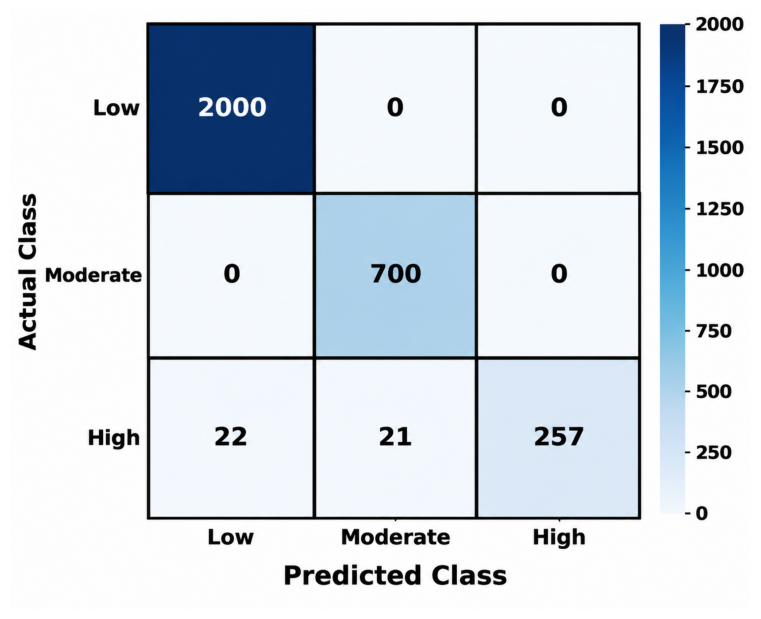

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import confusion_matrix

# Use the existing prepared test sequences and labels
model_path = (
    r"E:\Projects\5_Data Mining\Output\Steps_6_to_8\IGEO_Optimized_ILSTM_Model.keras"
)

# Load the saved model
model = tf.keras.models.load_model(
    model_path,
    compile=False
)

# Generate predictions for exactly X_test
probabilities = model.predict(X_test, verbose=0)

# Convert probabilities to class labels
y_pred = np.argmax(probabilities, axis=-1)

# Flatten actual labels and predictions
y_true = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

# Ensure predictions and actual labels have matching lengths
if len(y_true) != len(y_pred):
    raise ValueError(
        f"Prediction/label mismatch: "
        f"{len(y_true)} actual labels vs "
        f"{len(y_pred)} predictions. "
        f"X_test shape: {X_test.shape}; "
        f"y_test shape: {y_test.shape}; "
        f"prediction shape: {probabilities.shape}. "
        "Check that X_test and y_test were prepared from the "
        "same test split and that the model output matches it."
    )

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

# Visualize only — no printing and no saving
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"],
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 14, "weight": "bold"},
    cbar=True
)

plt.xlabel("Predicted Class", fontsize=12, fontweight="bold")
plt.ylabel("Actual Class", fontsize=12, fontweight="bold")
plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold", rotation=0)
plt.tight_layout()
plt.show()